<a href="https://colab.research.google.com/github/hduperera/machine-learning-tutorials/blob/main/Credit_Card_Clustering_(Self_Study).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. Environment Setup & Data Loading

In [12]:
import pandas as pd
import numpy as np
url = 'https://raw.githubusercontent.com/hduperera/Datasets/refs/heads/main/CC%20Dataset%20for%20clustering.csv'
df = pd.read_csv(url)

print("Dataset shape:", df.shape)   # (rows, columns)
df.head()

Dataset shape: (8950, 18)


,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


### What do the columns mean?
| Column | Meaning |
|---|---|
| `BALANCE` | Amount left on the account to pay |
| `BALANCE_FREQUENCY` | How often the balance is updated (0–1) |
| `PURCHASES` | Total purchases = `ONEOFF_PURCHASES` + `INSTALLMENTS_PURCHASES` |
| `CASH_ADVANCE` | Cash withdrawn using the card (expensive borrowing) |
| `*_FREQUENCY` | How often the customer does that activity (0 = never, 1 = every month) |
| `*_TRX` | Number of transactions |
| `CREDIT_LIMIT` | Card limit |
| `PAYMENTS` / `MINIMUM_PAYMENTS` | Amount paid / minimum amount paid |
| `PRC_FULL_PAYMENT` | % of months the customer paid the full balance |
| `TENURE` | Months as a customer |

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   CUST_ID                           8950 non-null   object 
 1   BALANCE                           8950 non-null   float64
 2   BALANCE_FREQUENCY                 8950 non-null   float64
 3   PURCHASES                         8950 non-null   float64
 4   ONEOFF_PURCHASES                  8950 non-null   float64
 5   INSTALLMENTS_PURCHASES            8950 non-null   float64
 6   CASH_ADVANCE                      8950 non-null   float64
 7   PURCHASES_FREQUENCY               8950 non-null   float64
 8   ONEOFF_PURCHASES_FREQUENCY        8950 non-null   float64
 9   PURCHASES_INSTALLMENTS_FREQUENCY  8950 non-null   float64
 10  CASH_ADVANCE_FREQUENCY            8950 non-null   float64
 11  CASH_ADVANCE_TRX                  8950 non-null   int64  
 12  PURCHA

In [16]:
# Counting missing values per column
missing = df.isna().sum()
missing = missing[missing > 0]
print(missing)

CREDIT_LIMIT          1
MINIMUM_PAYMENTS    313
dtype: int64


In [18]:
print(f"\nMissing missing_payments: {missing.get('MINIMUM_PAYMENTS', 0) / len(df):.1%} of rows")


Missing missing_payments: 3.5% of rows


# 2. Exploratory Data Analysis (EDA)



Clustering is **distance-based**, so the *shape* of each feature's distribution matters a lot.

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401  (enables 3D plots)

# A fixed colour order for clusters (colour-blind-checked palette).
# Cluster 0 is always blue, cluster 1 always orange, etc. across ALL plots.
CLUSTER_COLORS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100',
                  '#e87ba4', '#008300', '#6250d6', '#e34948']
NOISE_COLOR = '#b5b4ae'          # grey for DBSCAN noise points (label -1)
MARKERS = ['o', 's', '^', 'D', 'v', 'P', 'X', '*']  # shape = second cue besides colour

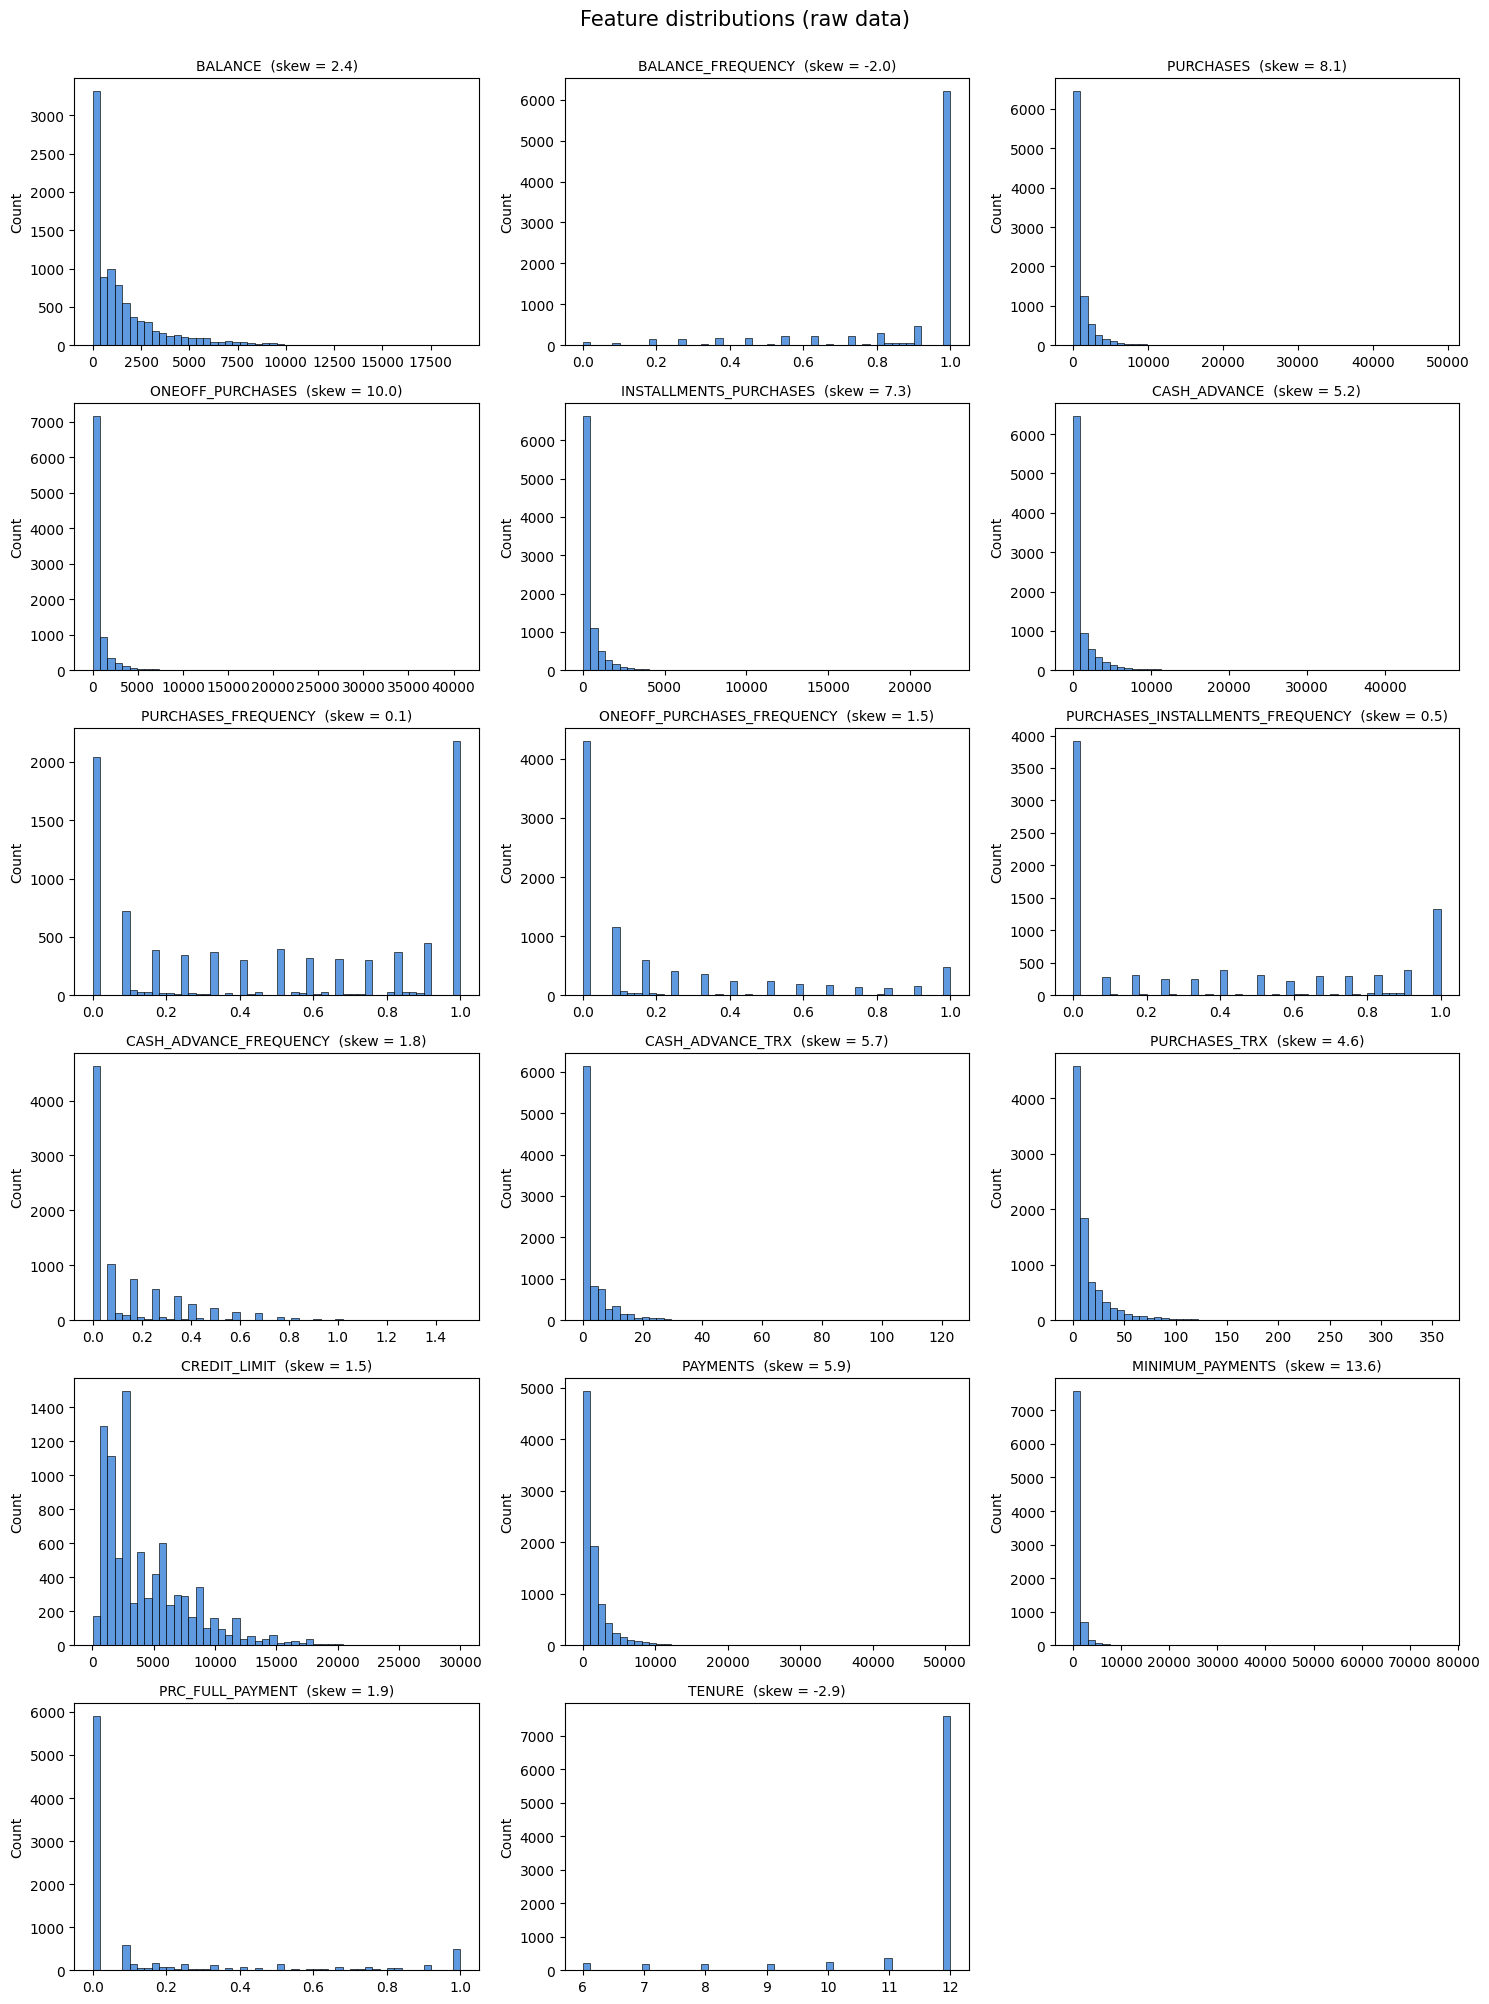

In [25]:
# Histograms of every numeric feature
num_cols = df.drop(columns='CUST_ID').columns

fig, axes = plt.subplots(6, 3, figsize=(15, 20))
for ax, col in zip(axes.flat, num_cols):
    sns.histplot(df[col].dropna(), bins=50, ax=ax, color=CLUSTER_COLORS[0])
    ax.set_title(f"{col}  (skew = {df[col].skew():.1f})", fontsize=10)
    ax.set_xlabel('')
for ax in axes.flat[len(num_cols):]:   # hide unused subplot slots
    ax.set_visible(False)
plt.suptitle('Feature distributions (raw data)', fontsize=15, y=1.0)
plt.tight_layout()
plt.show()


Observation: most money features (PURCHASES, CASH_ADVANCE, PAYMENTS, MINIMUM_PAYMENTS, …) have a huge spike near zero and a long tail to the right (skew > 2).

Why this matters: K-Means and Agglomerative use Euclidean distance. A handful of extreme spenders will be "far away" from everyone and will dominate the clustering. A log transform compresses the tail so that differences between, e.g., 100 and 1,000 count as much as between 1,000 and 10,000.

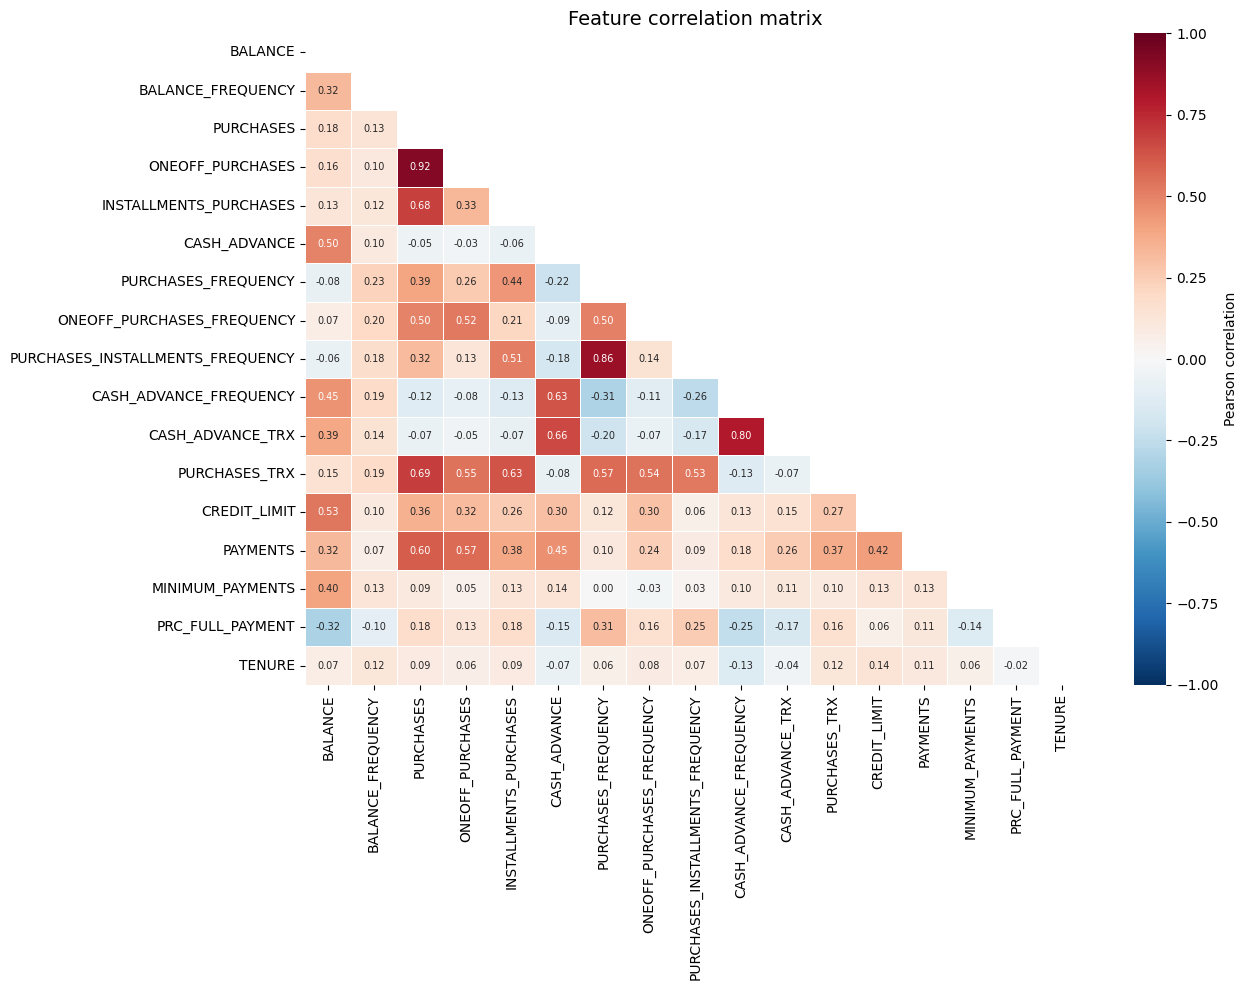

In [26]:
# Correlation heatmap: highly correlated features carry duplicate information.
corr = df[num_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))   # hide the upper triangle (mirror image)

plt.figure(figsize=(13, 10))
sns.heatmap(corr, mask=mask, cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            annot=True, fmt='.2f', annot_kws={'size': 7}, linewidths=0.5,
            cbar_kws={'label': 'Pearson correlation'})
plt.title('Feature correlation matrix', fontsize=14)
plt.tight_layout()
plt.show()

Observation: PURCHASES ≈ ONEOFF_PURCHASES + INSTALLMENTS_PURCHASES (strong correlations), and the cash-advance features move together. Correlated features effectively get extra weight in distance calculations. We'll handle this later with PCA for visualisation and for DBSCAN.

# 3. Preprocessing

In [30]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

Steps

1. Drop CUST_ID – an identifier, not a behaviour.
2. Impute missing values with the median (robust to outliers, unlike the mean).
3. Log-transform heavily skewed features (np.log1p = log(1 + x), safe for zeros).
4. Standardise every feature to mean 0, std 1 so that no feature dominates just because of its units (dollars vs. 0–1 frequencies).

In [31]:
# Step 1: keep only behavioural features
X = df.drop(columns='CUST_ID')

# Step 2: median imputation (MINIMUM_PAYMENTS has 313 NaN, CREDIT_LIMIT has 1)
imputer = SimpleImputer(strategy='median')
X = pd.DataFrame(imputer.fit_transform(X), columns=X.columns)

# Keep an untouched copy in real units -> used later to describe clusters
X_original = X.copy()

# Step 3: log-transform features whose skewness is above 2
skew = X.skew()
skewed_cols = skew[skew > 2].index.tolist()
print("Log-transformed columns:", skewed_cols)

X_log = X.copy()
X_log[skewed_cols] = np.log1p(X_log[skewed_cols])

# Step 4: standardise -> every column now has mean 0 and std 1
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)

print("Scaled data shape:", X_scaled.shape)
print("Means ≈ 0:", np.round(X_scaled.mean(axis=0)[:4], 3), "...")
print("Stds  ≈ 1:", np.round(X_scaled.std(axis=0)[:4], 3), "...")

Log-transformed columns: ['BALANCE', 'PURCHASES', 'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES', 'CASH_ADVANCE', 'CASH_ADVANCE_TRX', 'PURCHASES_TRX', 'PAYMENTS', 'MINIMUM_PAYMENTS']
Scaled data shape: (8950, 17)
Means ≈ 0: [0. 0. 0. 0.] ...
Stds  ≈ 1: [1. 1. 1. 1.] ...


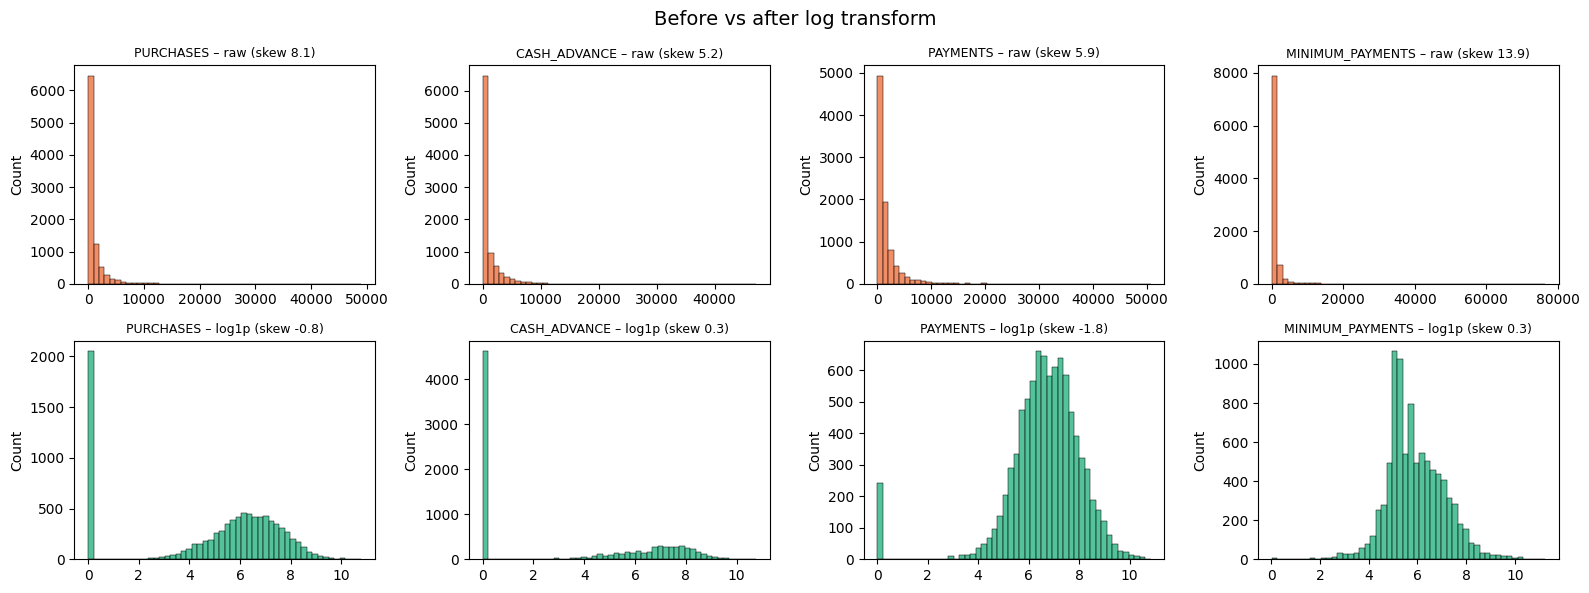

In [32]:
# Visual check: what did the log transform do to skewed features?
show = ['PURCHASES', 'CASH_ADVANCE', 'PAYMENTS', 'MINIMUM_PAYMENTS']
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for i, col in enumerate(show):
    sns.histplot(X_original[col], bins=50, ax=axes[0, i], color=CLUSTER_COLORS[1])
    axes[0, i].set_title(f"{col} – raw (skew {X_original[col].skew():.1f})", fontsize=9)
    sns.histplot(X_log[col], bins=50, ax=axes[1, i], color=CLUSTER_COLORS[2])
    axes[1, i].set_title(f"{col} – log1p (skew {X_log[col].skew():.1f})", fontsize=9)
    for r in (0, 1):
        axes[r, i].set_xlabel('')
plt.suptitle('Before vs after log transform', fontsize=14)
plt.tight_layout()
plt.show()

# 4. Dimensionality Reduction with PCA (for visualisation)
Since have **17 dimensions** it is impossible to plot. **PCA** (Principal Component Analysis) finds new axes (principal components) that capture the most variance. We use it to:
* draw clusters in 2D / 3D, and
* give DBSCAN a lower-dimensional space where density makes more sense (Section 7).

K-Means and Agglomerative are trained on the **full 17-D scaled data**; PCA is only for the pictures.

In [33]:
from sklearn.decomposition import PCA

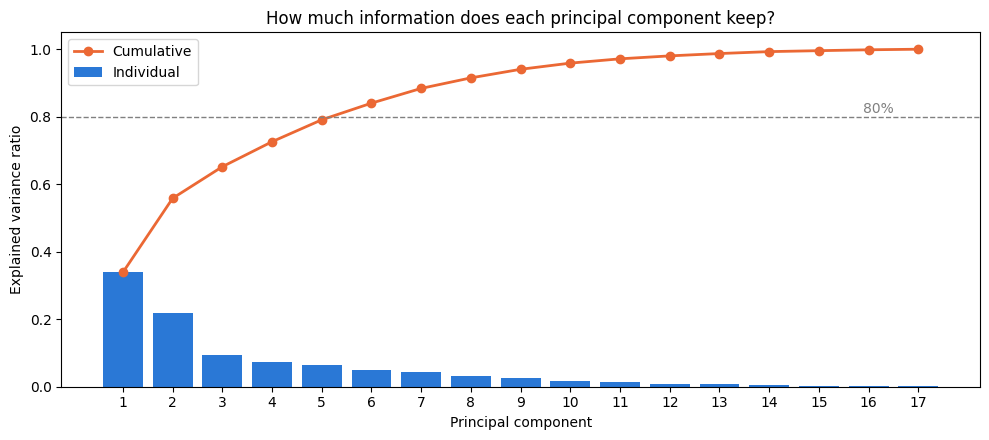

PC1+PC2 explain 55.8% of variance; PC1-3 explain 65.2%


In [34]:
pca_full = PCA(random_state=RANDOM_STATE).fit(X_scaled)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)

fig, ax = plt.subplots(figsize=(10, 4.5))
comps = np.arange(1, len(cum_var) + 1)
ax.bar(comps, pca_full.explained_variance_ratio_, color=CLUSTER_COLORS[0], label='Individual')
ax.plot(comps, cum_var, marker='o', color=CLUSTER_COLORS[1], lw=2, label='Cumulative')
ax.axhline(0.80, ls='--', color='grey', lw=1)
ax.text(len(cum_var) - 0.5, 0.81, '80%', ha='right', color='grey')
ax.set_xlabel('Principal component'); ax.set_ylabel('Explained variance ratio')
ax.set_title('How much information does each principal component keep?')
ax.set_xticks(comps); ax.legend()
plt.tight_layout(); plt.show()

print(f"PC1+PC2 explain {cum_var[1]:.1%} of variance; PC1-3 explain {cum_var[2]:.1%}")

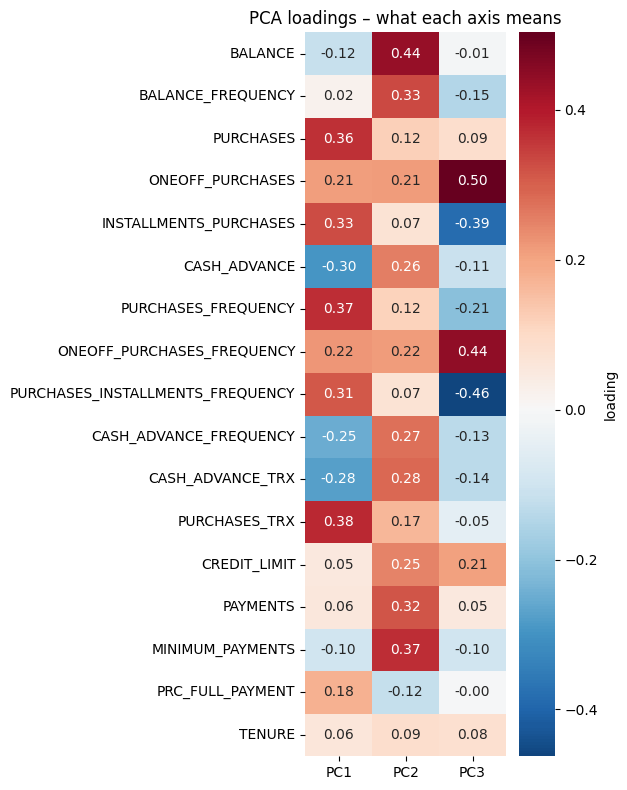

In [35]:
# Project the data onto the first 3 components (used in all scatter plots)
pca3 = PCA(n_components=3, random_state=RANDOM_STATE)
X_pca = pca3.fit_transform(X_scaled)

# Which original features drive each component? (the "loadings")
loadings = pd.DataFrame(pca3.components_.T, index=X.columns, columns=['PC1', 'PC2', 'PC3'])
plt.figure(figsize=(6, 8))
sns.heatmap(loadings, cmap='RdBu_r', center=0, annot=True, fmt='.2f', cbar_kws={'label': 'loading'})
plt.title('PCA loadings – what each axis means')
plt.tight_layout(); plt.show()

In [36]:
# Helper functions reused for every algorithm

def plot_clusters_2d(labels, title, ax=None, centers_pca=None):
    # Scatter of PC1 vs PC2 coloured by cluster. Noise (-1) is drawn in grey.
    if ax is None:
        fig, ax = plt.subplots(figsize=(9, 7))
    for lab in sorted(set(labels)):
        m = labels == lab
        if lab == -1:
            ax.scatter(X_pca[m, 0], X_pca[m, 1], s=8, c=NOISE_COLOR, marker='x',
                       alpha=0.5, label=f'Noise ({m.sum()})')
        else:
            ax.scatter(X_pca[m, 0], X_pca[m, 1], s=10, alpha=0.55,
                       c=CLUSTER_COLORS[lab % 8], marker=MARKERS[lab % 8],
                       edgecolors='none', label=f'Cluster {lab} ({m.sum()})')
    if centers_pca is not None:
        ax.scatter(centers_pca[:, 0], centers_pca[:, 1], s=260, c='black',
                   marker='*', edgecolors='white', linewidths=1.5, label='Centroids')
    ax.set_xlabel('PC1'); ax.set_ylabel('PC2'); ax.set_title(title)
    leg = ax.legend(markerscale=2, fontsize=8, loc='best')
    if centers_pca is not None:
        leg.legend_handles[-1].set_sizes([90])   # keep the centroid legend icon a sensible size
    return ax


def plot_silhouette(X_data, labels, title, ax=None):
    # Silhouette "knife" plot: one horizontal bar per sample, grouped by cluster.
    # Bars to the right of 0 = well matched to own cluster; left of 0 = maybe misassigned.
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 6))
    sil_vals = silhouette_samples(X_data, labels)
    avg = sil_vals.mean()
    y_low = 10
    for lab in sorted(set(labels)):
        vals = np.sort(sil_vals[labels == lab])
        y_up = y_low + len(vals)
        ax.fill_betweenx(np.arange(y_low, y_up), 0, vals,
                         color=CLUSTER_COLORS[lab % 8], alpha=0.8)
        ax.text(-0.08, y_low + len(vals) / 2, str(lab), fontsize=10)
        y_low = y_up + 10   # gap between clusters
    ax.axvline(avg, color='black', ls='--', lw=1.2)
    ax.text(avg + 0.01, y_low * 0.98, f'mean = {avg:.3f}', fontsize=9)
    ax.set_xlabel('Silhouette coefficient'); ax.set_ylabel('Cluster')
    ax.set_yticks([]); ax.set_xlim(-0.3, 1); ax.set_title(title)
    return ax


def plot_cluster_sizes(labels, title, ax=None):
    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 4))
    counts = pd.Series(labels).value_counts().sort_index()
    colors = [NOISE_COLOR if l == -1 else CLUSTER_COLORS[l % 8] for l in counts.index]
    names = ['Noise' if l == -1 else f'C{l}' for l in counts.index]
    bars = ax.bar(names, counts.values, color=colors)
    for b, v in zip(bars, counts.values):
        ax.text(b.get_x() + b.get_width() / 2, v, f'{v}\n({v / len(labels):.0%})',
                ha='center', va='bottom', fontsize=9)
    ax.set_ylabel('Customers'); ax.set_title(title)
    ax.set_ylim(0, counts.max() * 1.2)
    return ax


def evaluate(X_data, labels, ignore_noise=True):
    # Return the three internal metrics. Noise points are excluded for DBSCAN.
    labels = np.asarray(labels)
    if ignore_noise:
        mask = labels != -1
        X_data, labels = X_data[mask], labels[mask]
    if len(set(labels)) < 2:
        return dict(silhouette=np.nan, davies_bouldin=np.nan, calinski_harabasz=np.nan)
    return dict(silhouette=silhouette_score(X_data, labels),
                davies_bouldin=davies_bouldin_score(X_data, labels),
                calinski_harabasz=calinski_harabasz_score(X_data, labels))

### The three evaluation metrics
| Metric | Range | Better | Intuition |
|---|---|---|---|
| **Silhouette** | −1 … 1 | **higher** | How close a point is to its own cluster vs. the nearest other cluster |
| **Davies–Bouldin (DB)** | 0 … ∞ | **lower** | Average "similarity" between each cluster and its most similar neighbour |
| **Calinski–Harabasz (CH)** | 0 … ∞ | **higher** | Ratio of between-cluster spread to within-cluster spread |

In [37]:
# Clustering algorithms
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors

# Evaluation metrics (no labels needed)
from sklearn.metrics import (silhouette_score, silhouette_samples,
                             davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score)

# 5. K-Means Clustering
How it works: pick k centroids → assign each point to the nearest centroid → move each centroid to the mean of its points → repeat until stable.

In [38]:
k_range = range(2, 11)
km_results = []

for k in k_range:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=RANDOM_STATE)
    labels = km.fit_predict(X_scaled)
    scores = evaluate(X_scaled, labels, ignore_noise=False)
    scores.update(k=k, inertia=km.inertia_,                       # inertia = within-cluster sum of squares
                  smallest_cluster=np.bincount(labels).min() / len(labels))
    km_results.append(scores)

km_results = pd.DataFrame(km_results).set_index('k')
km_results.round(3)

,silhouette,davies_bouldin,calinski_harabasz,inertia,smallest_cluster
k,,,,,
2,0.252,1.498,3065.116,113329.397,0.353
3,0.225,1.676,2641.186,95667.411,0.322
4,0.215,1.680,2255.391,86629.344,0.182
5,0.219,1.588,2124.623,78022.372,0.157
6,0.218,1.456,2007.013,71701.619,0.113
7,0.220,1.419,1842.506,68040.599,0.054
8,0.217,1.443,1716.504,64918.271,0.053
9,0.202,1.526,1610.555,62329.705,0.046
10,0.185,1.508,1566.970,59030.403,0.047


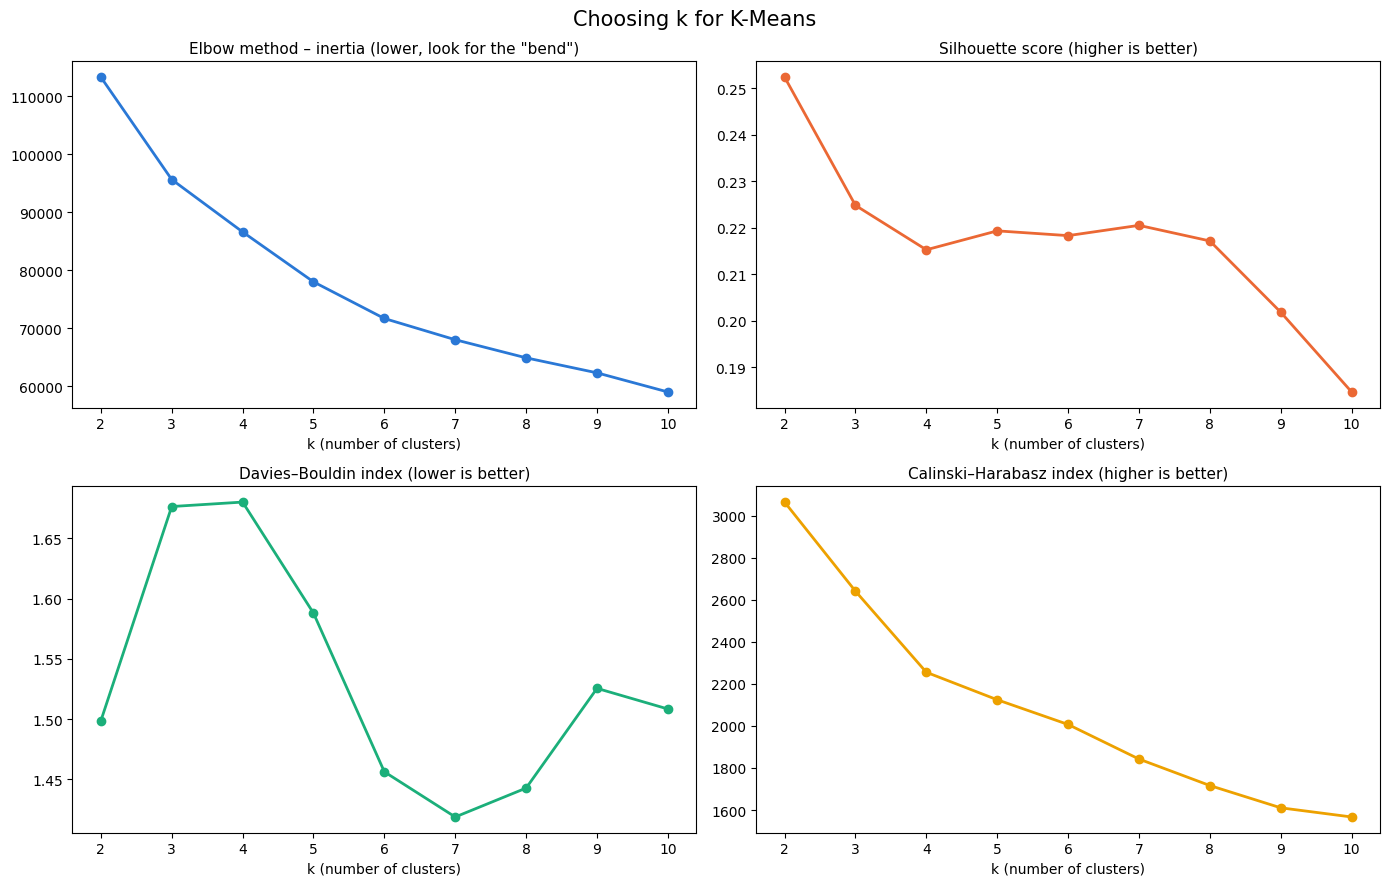

In [39]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
ks = km_results.index

panels = [('inertia', 'Elbow method – inertia (lower, look for the "bend")', 0),
          ('silhouette', 'Silhouette score (higher is better)', 1),
          ('davies_bouldin', 'Davies–Bouldin index (lower is better)', 2),
          ('calinski_harabasz', 'Calinski–Harabasz index (higher is better)', 3)]

for ax, (col, title, c) in zip(axes.flat, panels):
    ax.plot(ks, km_results[col], marker='o', lw=2, color=CLUSTER_COLORS[c])
    ax.set_title(title, fontsize=11); ax.set_xlabel('k (number of clusters)')
    ax.set_xticks(list(ks))

plt.suptitle('Choosing k for K-Means', fontsize=15)
plt.tight_layout(); plt.show()

## Choosing k – reading the four charts together


Silhouette and Calinski–Harabasz both peak at k = 2, but two segments ("buyers" vs "cash users") are too coarse to be useful for marketing.


From k = 3 to 8 the silhouette is almost flat (~0.215–0.225) – so moving to a more detailed segmentation costs very little.

The elbow curve has no sharp bend; it flattens gradually after k ≈ 5–6.
Davies–Bouldin disagrees: it is worst at k = 3–4 and best at k = 7.

Seven segments, however, are hard for a marketing team to act on.

At k = 4 every cluster still holds > 15% of customers (no tiny, unstable clusters)

Chose k = 4. The metrics do not single out one "correct" k for this data (this is very common with real customer data), so we pick the most interpretable option inside the range where the metrics are roughly equal. Metrics narrow the options; domain sense makes the final call – and you should always say so honestly in a report.

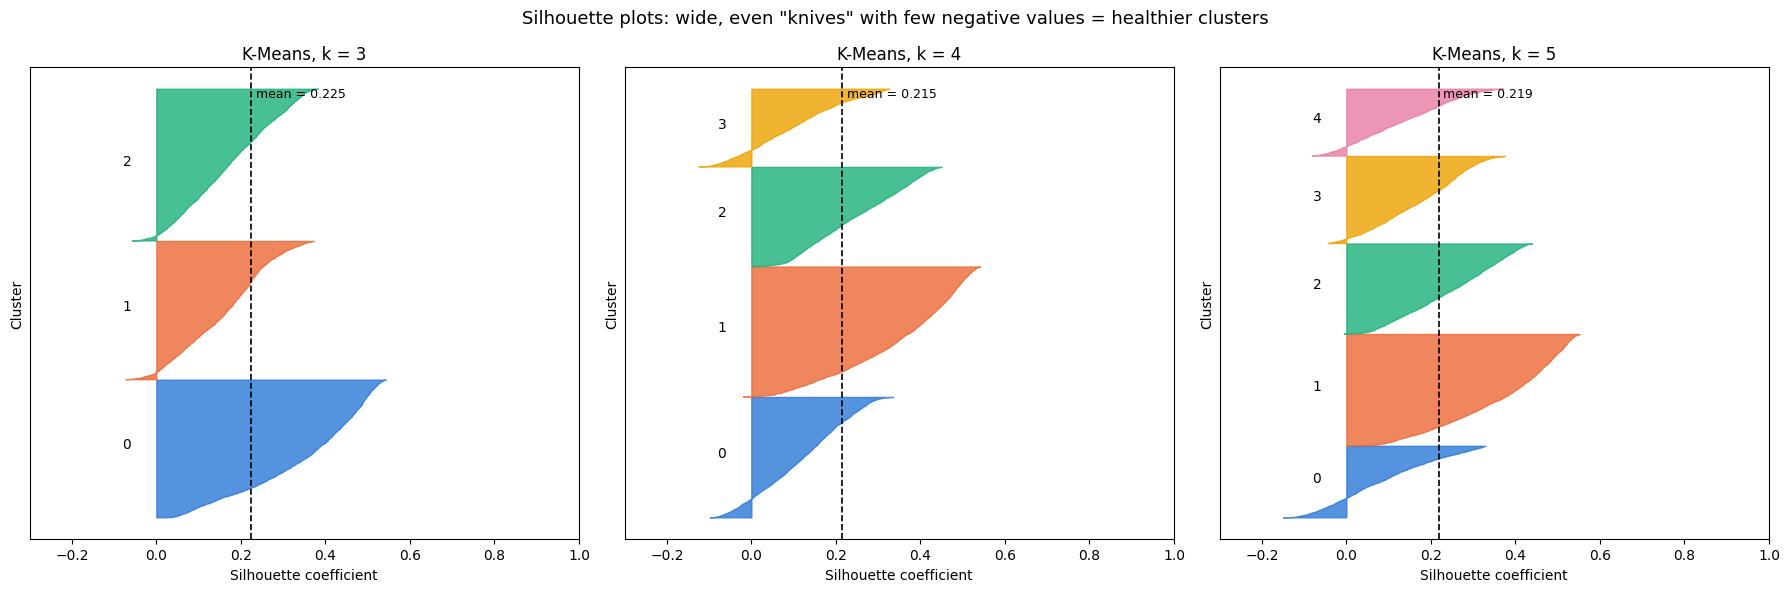

In [40]:
# Silhouette knife plots for k = 3, 4, 5 side-by-side
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, k in zip(axes, [3, 4, 5]):
    lab = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(X_scaled)
    plot_silhouette(X_scaled, lab, f'K-Means, k = {k}', ax=ax)
plt.suptitle('Silhouette plots: wide, even "knives" with few negative values = healthier clusters', fontsize=13)
plt.tight_layout(); plt.show()

In [41]:
BEST_K = 4

# Final, tuned K-Means:
#  - init='k-means++' : smart initial centroids (spread out), faster & more stable than random
#  - n_init=50        : run 50 different starts and keep the best (lowest inertia)
#  - max_iter=500     : allow enough iterations to converge
kmeans = KMeans(n_clusters=BEST_K, init='k-means++', n_init=50, max_iter=500,
                random_state=RANDOM_STATE)
kmeans_labels = kmeans.fit_predict(X_scaled)

km_scores = evaluate(X_scaled, kmeans_labels, ignore_noise=False)
print(f"Tuned K-Means (k={BEST_K})")
for name, v in km_scores.items():
    print(f"  {name:<18}: {v:.4f}")

Tuned K-Means (k=4)
  silhouette        : 0.2163
  davies_bouldin    : 1.6833
  calinski_harabasz : 2256.1950


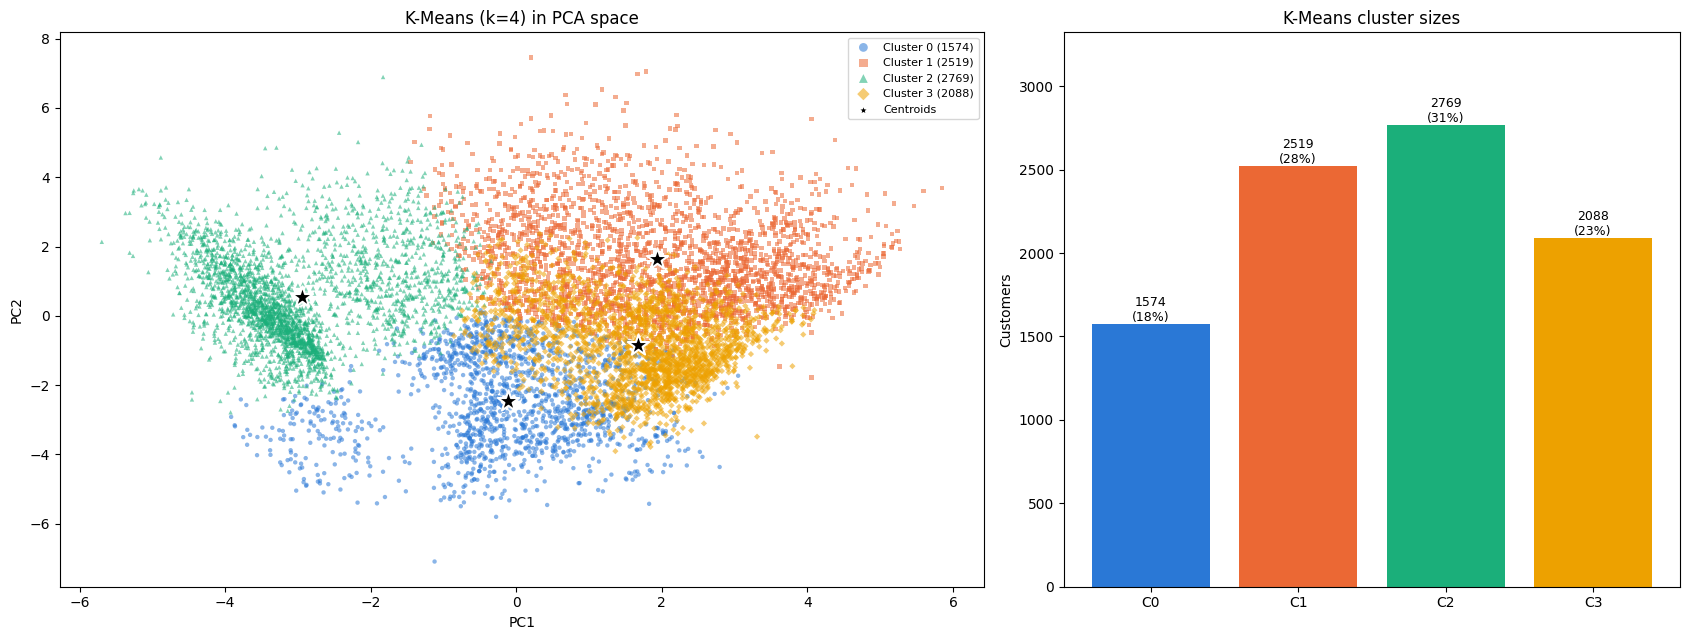

In [42]:
# Visualise the final K-Means clusters
centers_pca = pca3.transform(kmeans.cluster_centers_)   # project centroids into PCA space too

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw={'width_ratios': [1.5, 1]})
plot_clusters_2d(kmeans_labels, f'K-Means (k={BEST_K}) in PCA space', ax=axes[0], centers_pca=centers_pca)
plot_cluster_sizes(kmeans_labels, 'K-Means cluster sizes', ax=axes[1])
plt.tight_layout(); plt.show()

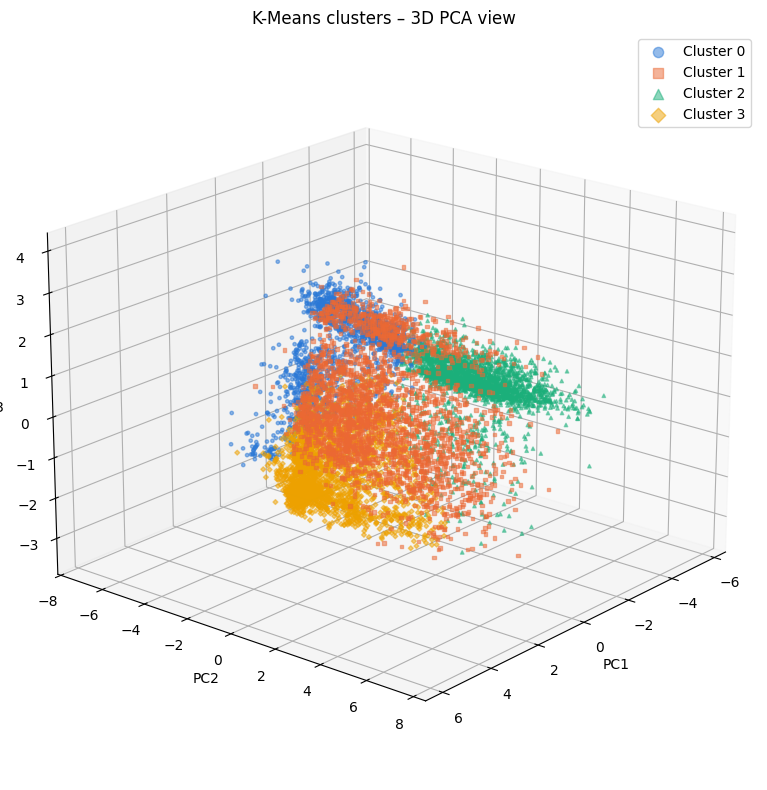

In [43]:
# 3D view using the first three principal components
fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(111, projection='3d')
for lab in range(BEST_K):
    m = kmeans_labels == lab
    ax.scatter(X_pca[m, 0], X_pca[m, 1], X_pca[m, 2], s=6, alpha=0.5,
               c=CLUSTER_COLORS[lab], marker=MARKERS[lab], label=f'Cluster {lab}')
ax.set_xlabel('PC1'); ax.set_ylabel('PC2'); ax.set_zlabel('PC3')
ax.set_title('K-Means clusters – 3D PCA view')
ax.view_init(elev=20, azim=40)
ax.legend(markerscale=3)
plt.tight_layout(); plt.show()

# 6. Agglomerative (Hierarchical) Clustering
**How it works (bottom-up):** start with every customer as its own cluster → repeatedly **merge the two closest clusters** → stop when *k* clusters remain.

"Closest" depends on the **linkage** method:
| Linkage | Distance between two clusters = | Behaviour |
|---|---|---|
| `ward` | increase in within-cluster variance after merging | compact, similar-sized clusters (like K-Means) |
| `complete` | the **farthest** pair of points | compact, but sensitive to outliers |
| `average` | the **average** of all pairwise distances | in-between |
| `single` | the **closest** pair of points | creates long "chains"; usually one giant cluster |

Hyperparameters to tune: **linkage** and **n_clusters**.

In [44]:
# --- Hierarchical clustering tools for the dendrogram ---
from scipy.cluster.hierarchy import linkage, dendrogram

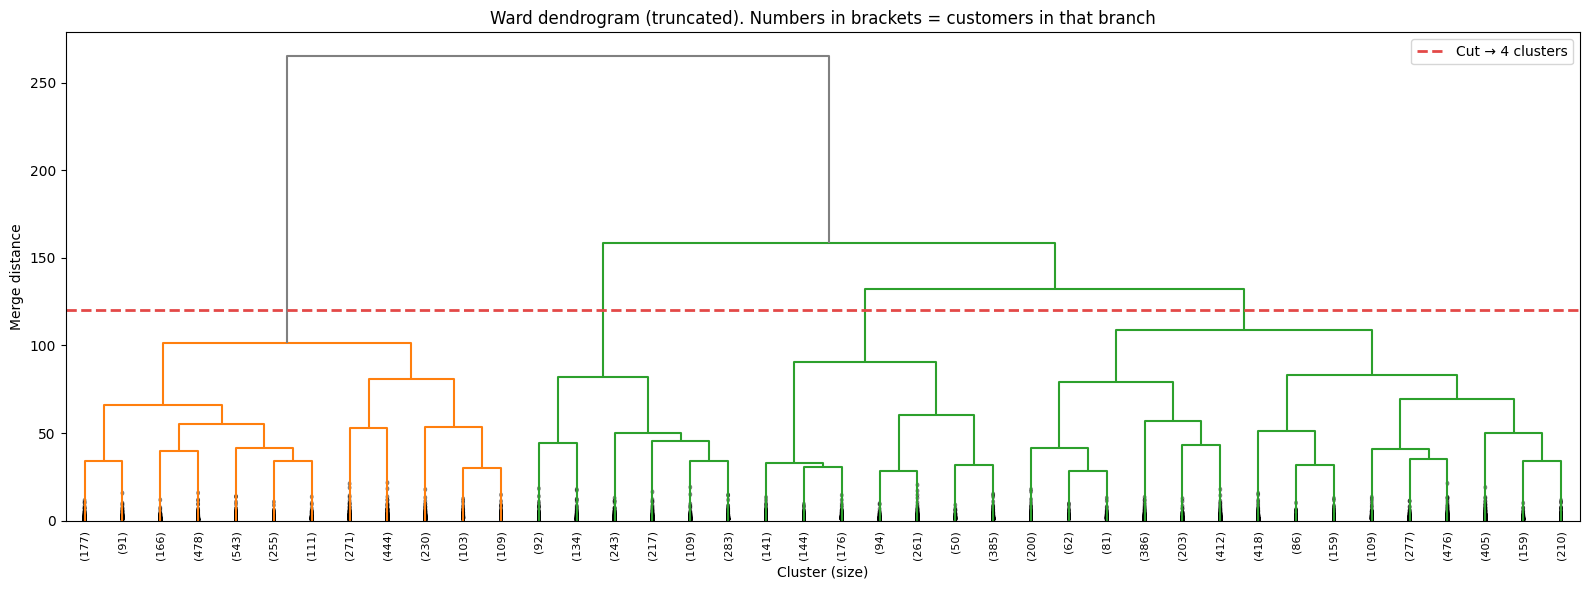

In [47]:
# Dendrogram: shows the full merge history. Height of a merge = distance at which clusters joined.
# Computing the full linkage on 8,950 points takes a few seconds.
Z_ward = linkage(X_scaled, method='ward')

plt.figure(figsize=(16, 6))
dendrogram(Z_ward, truncate_mode='lastp', p=40,      # only show the last 40 merges
           leaf_rotation=90, leaf_font_size=8, show_contracted=True,
           color_threshold=None, above_threshold_color='grey')
# Draw a horizontal "cut" line that produces 4 clusters
cut_height = (Z_ward[-4, 2] + Z_ward[-3, 2]) / 2
plt.axhline(cut_height, color=CLUSTER_COLORS[7], ls='--', lw=2, label='Cut → 4 clusters')
plt.title('Ward dendrogram (truncated). Numbers in brackets = customers in that branch')
plt.xlabel('Cluster (size)'); plt.ylabel('Merge distance')
plt.legend(); plt.tight_layout(); plt.show()

long vertical lines mean those groups are far apart before merging – a natural place to "cut". Cutting where the line crosses 4 vertical branches gives 4 clusters. The very last merge (top) happens at a much larger distance than the rest, which is why silhouette favours 2 clusters; below that, the next splits (3, 4, 5 clusters) happen at similar heights, matching the "flat" silhouette we saw for K-Means.

In [48]:
# Grid search over linkage x number of clusters
linkages = ['ward', 'complete', 'average', 'single']
k_values = range(2, 9)
agg_results = []

for link in linkages:
    for k in k_values:
        labels = AgglomerativeClustering(n_clusters=k, linkage=link).fit_predict(X_scaled)
        sizes = np.bincount(labels)
        s = evaluate(X_scaled, labels, ignore_noise=False)
        s.update(linkage=link, k=k, smallest_cluster=sizes.min() / len(labels))
        agg_results.append(s)

agg_results = pd.DataFrame(agg_results)
agg_results.round(3).head(10)

,silhouette,davies_bouldin,calinski_harabasz,linkage,k,smallest_cluster
0,0.233,1.561,2696.667,ward,2,0.333
1,0.211,1.666,2048.660,ward,3,0.120
2,0.175,1.878,1761.804,ward,4,0.120
3,0.153,1.943,1555.708,ward,5,0.120
4,0.138,2.045,1428.436,ward,6,0.120
5,0.137,1.911,1326.366,ward,7,0.052
6,0.131,1.951,1244.691,ward,8,0.052
7,0.142,2.462,1006.133,complete,2,0.234
8,0.065,2.132,810.907,complete,3,0.051
9,0.037,2.238,791.902,complete,4,0.051


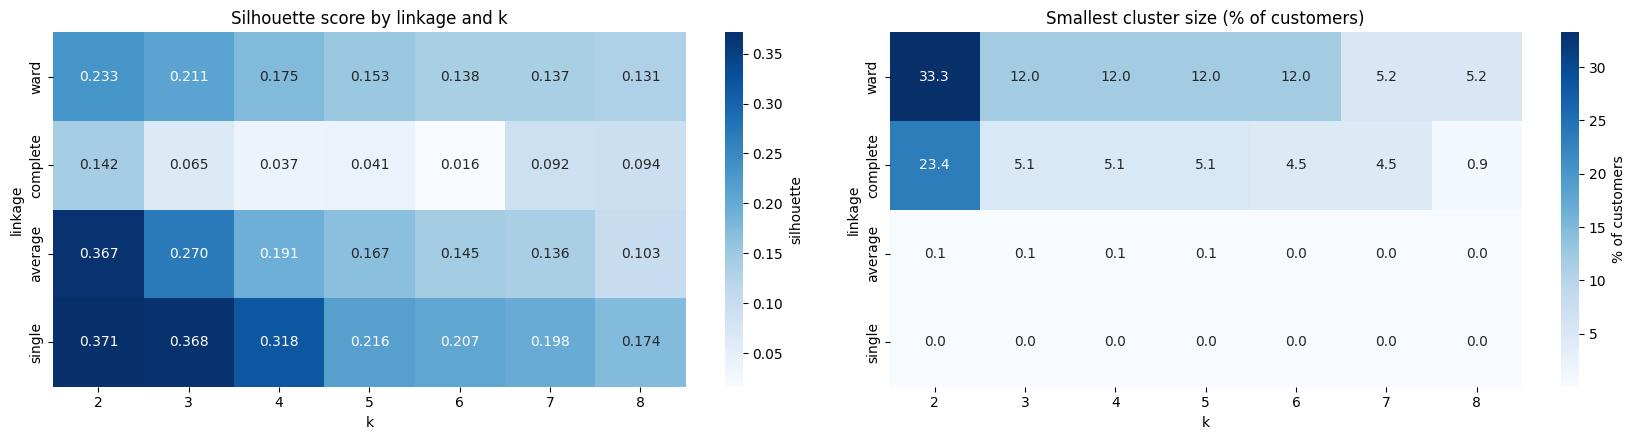

In [50]:
# Heatmaps: silhouette (left) and size of the smallest cluster (right)
sil_pivot = agg_results.pivot(index='linkage', columns='k', values='silhouette').loc[linkages]
small_pivot = agg_results.pivot(index='linkage', columns='k', values='smallest_cluster').loc[linkages]

fig, axes = plt.subplots(1, 2, figsize=(17, 4.5))
sns.heatmap(sil_pivot, annot=True, fmt='.3f', cmap='Blues', ax=axes[0],
            cbar_kws={'label': 'silhouette'})
axes[0].set_title('Silhouette score by linkage and k')
sns.heatmap(small_pivot * 100, annot=True, fmt='.1f', cmap='Blues', ax=axes[1],
            cbar_kws={'label': '% of customers'})
axes[1].set_title('Smallest cluster size (% of customers)')
plt.tight_layout(); plt.show()

Some silhouette scores look better than Ward's, but the right-hand heatmap shows the smallest cluster holds < 1% of customers. In reality these models put almost everyone in one giant cluster and isolate a few outliers. That is outlier detection, not segmentation.

Rule we apply: only accept solutions where every cluster has at least 5% of customers, then pick the best silhouette among those.

In [51]:
MIN_CLUSTER_FRAC = 0.05   # every cluster must hold >= 5% of customers

valid = agg_results[agg_results['smallest_cluster'] >= MIN_CLUSTER_FRAC]
print("Top valid configurations:")
display(valid.sort_values('silhouette', ascending=False).head(6).round(3))

# For a fair comparison with K-Means we also look at the best valid model with the SAME k
best_same_k = valid[valid['k'] == BEST_K].sort_values('silhouette', ascending=False).iloc[0]
print(f"\nBest valid model with k={BEST_K}: linkage = {best_same_k['linkage']}, "
      f"silhouette = {best_same_k['silhouette']:.4f}")

Top valid configurations:


,silhouette,davies_bouldin,calinski_harabasz,linkage,k,smallest_cluster
0,0.233,1.561,2696.667,ward,2,0.333
1,0.211,1.666,2048.660,ward,3,0.120
2,0.175,1.878,1761.804,ward,4,0.120
3,0.153,1.943,1555.708,ward,5,0.120
7,0.142,2.462,1006.133,complete,2,0.234
4,0.138,2.045,1428.436,ward,6,0.120



Best valid model with k=4: linkage = ward, silhouette = 0.1753


Tuned Agglomerative (ward, k=4)
  silhouette        : 0.1753
  davies_bouldin    : 1.8784
  calinski_harabasz : 1761.8035


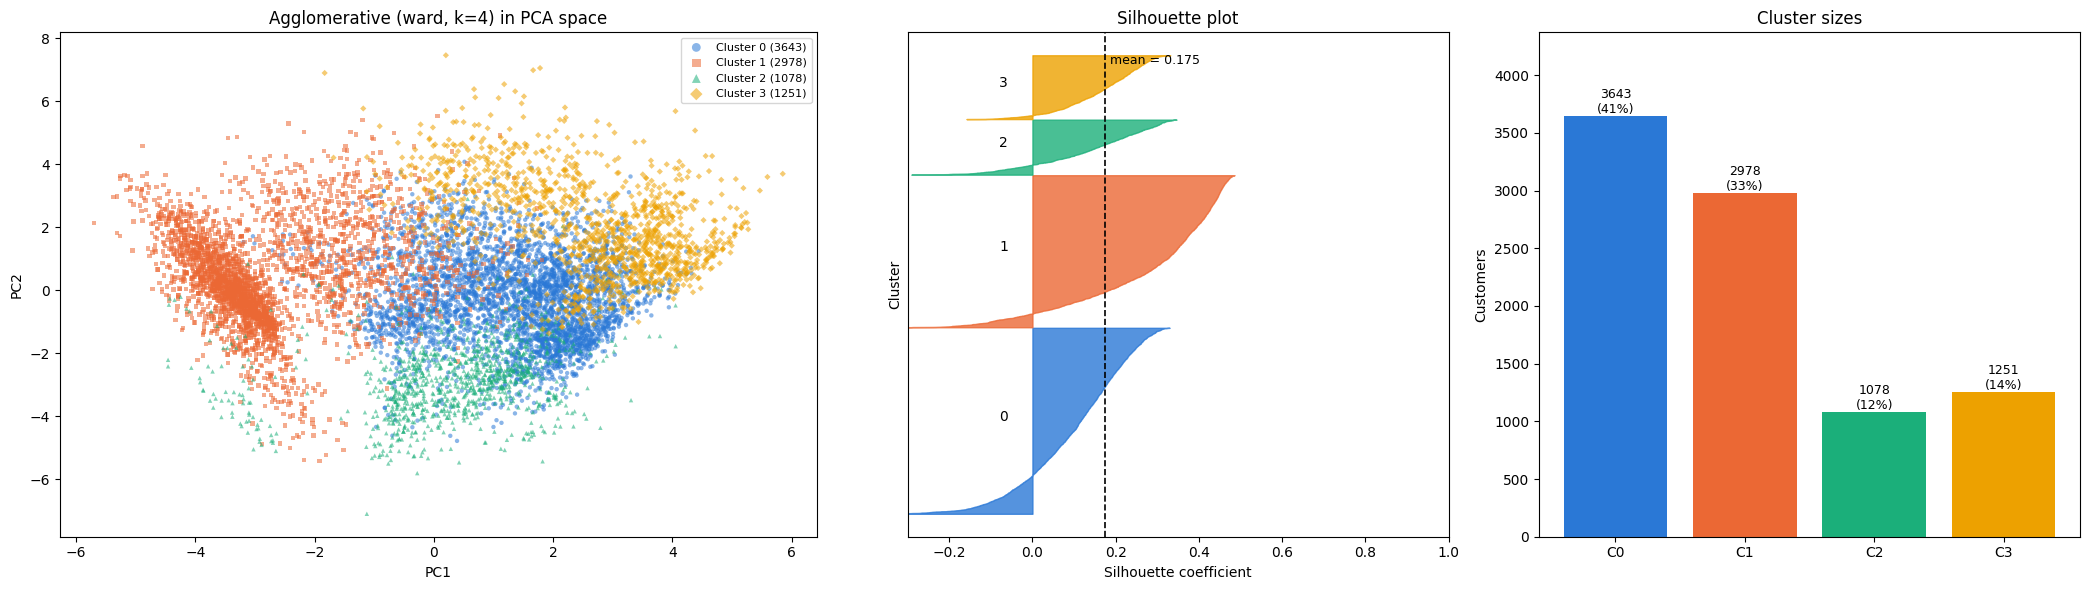

Tuned Agglomerative (ward, k=4)
  silhouette        : 0.1753
  davies_bouldin    : 1.8784
  calinski_harabasz : 1761.8035


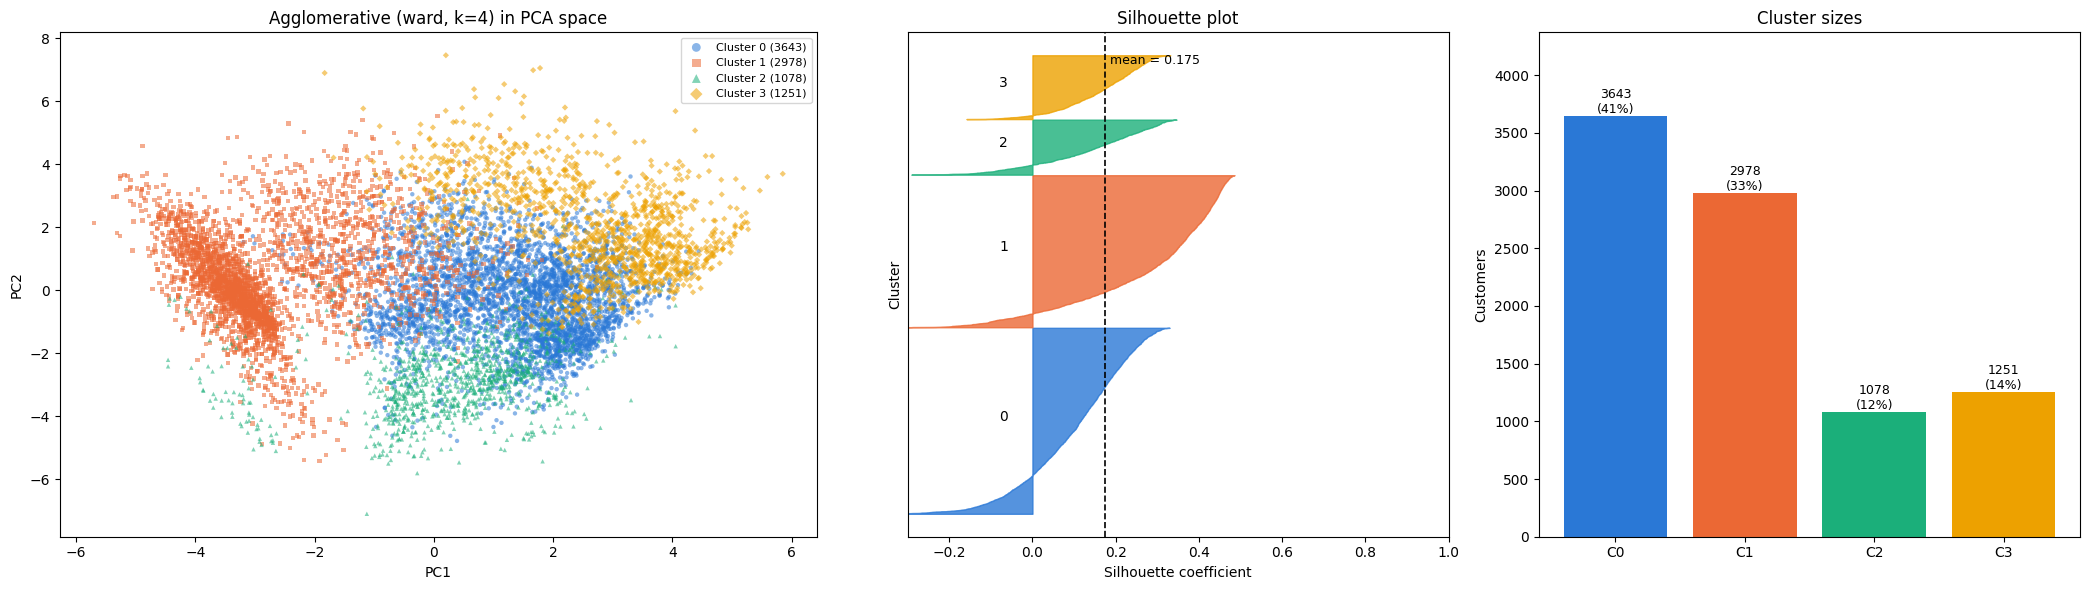

In [52]:
# Final tuned Agglomerative model (same k as K-Means so their segments can be compared)
AGG_LINKAGE = best_same_k['linkage']
agg = AgglomerativeClustering(n_clusters=BEST_K, linkage=AGG_LINKAGE)
agg_labels = agg.fit_predict(X_scaled)

agg_scores = evaluate(X_scaled, agg_labels, ignore_noise=False)
print(f"Tuned Agglomerative ({AGG_LINKAGE}, k={BEST_K})")
for name, v in agg_scores.items():
    print(f"  {name:<18}: {v:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(21, 6), gridspec_kw={'width_ratios': [1.4, 1, 1]})
plot_clusters_2d(agg_labels, f'Agglomerative ({AGG_LINKAGE}, k={BEST_K}) in PCA space', ax=axes[0])
plot_silhouette(X_scaled, agg_labels, 'Silhouette plot', ax=axes[1])
plot_cluster_sizes(agg_labels, 'Cluster sizes', ax=axes[2])
plt.tight_layout(); plt.show()# Final tuned Agglomerative model (same k as K-Means so their segments can be compared)
AGG_LINKAGE = best_same_k['linkage']
agg = AgglomerativeClustering(n_clusters=BEST_K, linkage=AGG_LINKAGE)
agg_labels = agg.fit_predict(X_scaled)

agg_scores = evaluate(X_scaled, agg_labels, ignore_noise=False)
print(f"Tuned Agglomerative ({AGG_LINKAGE}, k={BEST_K})")
for name, v in agg_scores.items():
    print(f"  {name:<18}: {v:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(21, 6), gridspec_kw={'width_ratios': [1.4, 1, 1]})
plot_clusters_2d(agg_labels, f'Agglomerative ({AGG_LINKAGE}, k={BEST_K}) in PCA space', ax=axes[0])
plot_silhouette(X_scaled, agg_labels, 'Silhouette plot', ax=axes[1])
plot_cluster_sizes(agg_labels, 'Cluster sizes', ax=axes[2])
plt.tight_layout(); plt.show()

# 7. DBSCAN (Density-Based Clustering)
**How it works:** a point is a **core point** if at least `min_samples` points lie within radius `eps`. Clusters grow by connecting core points that are within `eps` of each other. Points that belong to no dense region are labelled **noise (−1)**.

**Advantages:** no need to choose *k*, finds arbitrary shapes, flags outliers.
**Weakness:** struggles when the data has **no clear density gaps** or is **high-dimensional**.

### Why the original version gave only 1 cluster
`eps = 2.5` on 17-dimensional scaled data: in high dimensions, distances between all points become similar (the **curse of dimensionality**), so one radius either connects everyone (1 cluster) or no one (all noise).

**Fixes we apply:**
1. Run DBSCAN on the first **3 principal components** (a denser, lower-dimensional space).
2. Use a **k-distance plot** to choose a sensible range for `eps`.
3. **Grid search** `eps` × `min_samples`, while controlling the amount of noise.

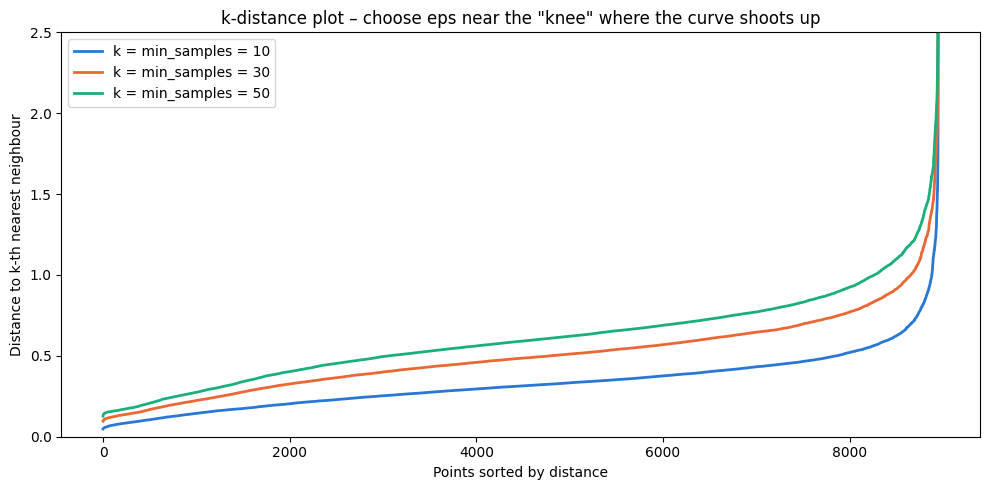

In [53]:
# DBSCAN works in PCA space (3 components, ~65% of the variance)
X_db = X_pca

# k-distance plot: for every point, distance to its k-th nearest neighbour, sorted.
# The "knee" of this curve is a good starting eps: beyond it, points are in sparse areas.
fig, ax = plt.subplots(figsize=(10, 5))
for i, k in enumerate([10, 30, 50]):
    nn = NearestNeighbors(n_neighbors=k).fit(X_db)
    dist, _ = nn.kneighbors(X_db)
    ax.plot(np.sort(dist[:, -1]), lw=2, color=CLUSTER_COLORS[i], label=f'k = min_samples = {k}')
ax.set_ylim(0, 2.5)
ax.set_xlabel('Points sorted by distance'); ax.set_ylabel('Distance to k-th nearest neighbour')
ax.set_title('k-distance plot – choose eps near the "knee" where the curve shoots up')
ax.legend(); plt.tight_layout(); plt.show()

In [54]:
# Grid search over eps and min_samples
eps_values = np.round(np.arange(0.20, 1.25, 0.05), 2)
min_samples_values = [10, 20, 30, 50, 75]
db_results = []

for eps in eps_values:
    for ms in min_samples_values:
        labels = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_db)
        core = labels[labels != -1]
        n_clusters = len(set(core))
        noise_frac = np.mean(labels == -1)
        sizes = np.bincount(core) if len(core) else np.array([0])
        # silhouette on non-noise points only (on a sample of 3000 for speed)
        sil = np.nan
        if n_clusters >= 2:
            try:
                sil = silhouette_score(X_db[labels != -1], core,
                                       sample_size=min(3000, len(core)), random_state=RANDOM_STATE)
            except ValueError:
                pass
        db_results.append(dict(eps=eps, min_samples=ms, n_clusters=n_clusters,
                               noise_frac=noise_frac,
                               smallest_cluster=sizes.min() / len(labels),
                               silhouette=sil))

db_results = pd.DataFrame(db_results)
print(f"Tested {len(db_results)} configurations")
db_results.sort_values('silhouette', ascending=False).head(8).round(3)

Tested 105 configurations


,eps,min_samples,n_clusters,noise_frac,smallest_cluster,silhouette
14,0.30,75,2,0.849,0.015,0.848
8,0.25,50,2,0.863,0.007,0.847
7,0.25,30,2,0.799,0.042,0.827
13,0.30,50,2,0.800,0.039,0.827
19,0.35,75,2,0.795,0.042,0.827
24,0.40,75,2,0.760,0.061,0.813
1,0.20,20,3,0.822,0.002,0.707
18,0.35,50,4,0.747,0.006,0.620


Very high silhouette scores – but 60–80% of customers are labelled noise! Because noise points are excluded from the silhouette calculation, DBSCAN can "cheat" by throwing away every difficult point. The plot below makes this trade-off visible.

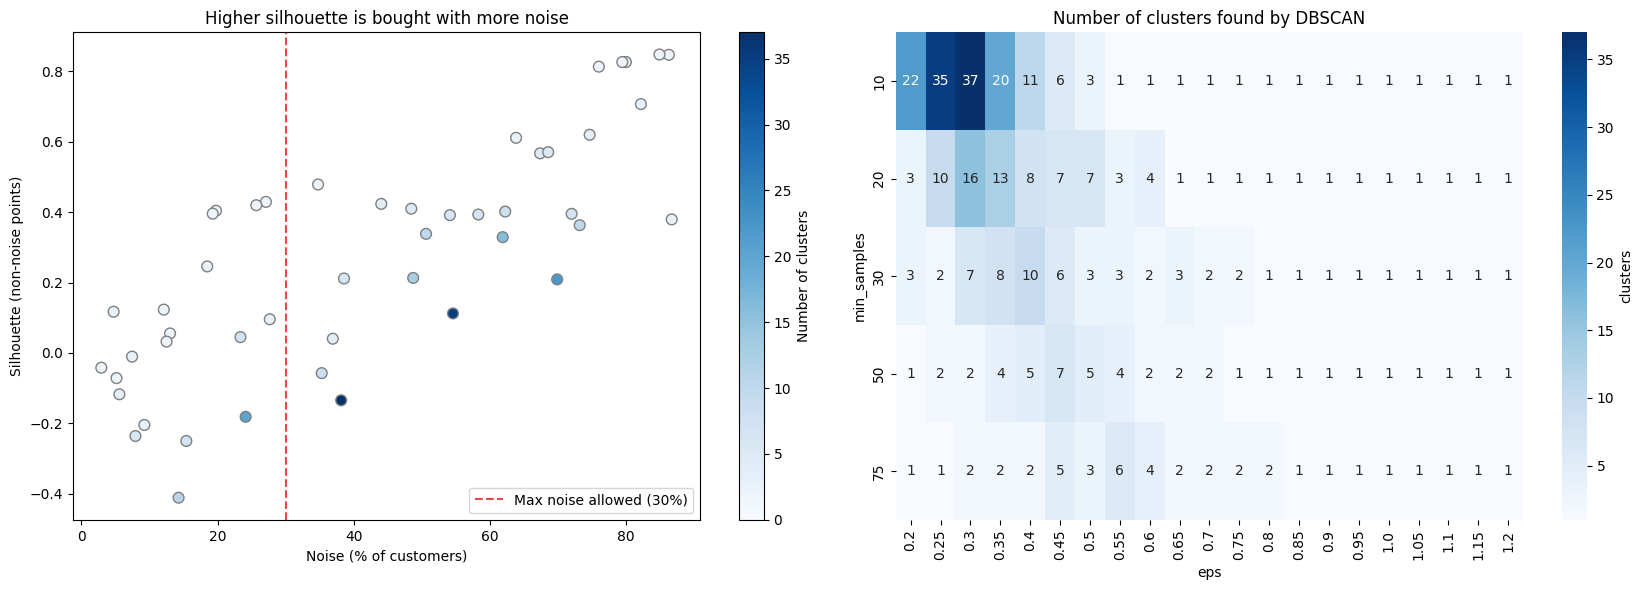

In [55]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6))

# Left: silhouette vs noise fraction for every configuration
v = db_results.dropna(subset=['silhouette'])
sc = axes[0].scatter(v['noise_frac'] * 100, v['silhouette'], c=v['n_clusters'],
                     cmap='Blues', s=60, edgecolors='grey', vmin=0)
axes[0].axvline(30, color=CLUSTER_COLORS[7], ls='--', lw=1.5, label='Max noise allowed (30%)')
axes[0].set_xlabel('Noise (% of customers)'); axes[0].set_ylabel('Silhouette (non-noise points)')
axes[0].set_title('Higher silhouette is bought with more noise')
plt.colorbar(sc, ax=axes[0], label='Number of clusters'); axes[0].legend()

# Right: number of clusters for each (eps, min_samples)
n_pivot = db_results.pivot(index='min_samples', columns='eps', values='n_clusters')
sns.heatmap(n_pivot, annot=True, fmt='d', cmap='Blues', ax=axes[1], cbar_kws={'label': 'clusters'})
axes[1].set_title('Number of clusters found by DBSCAN')
plt.tight_layout(); plt.show()

In [56]:
# Selection rule: at least 2 clusters, each >= 2% of customers, and at most 30% noise.
MAX_NOISE = 0.30
candidates = db_results[(db_results['n_clusters'] >= 2) &
                        (db_results['smallest_cluster'] >= 0.02) &
                        (db_results['noise_frac'] <= MAX_NOISE)]
display(candidates.sort_values('silhouette', ascending=False).head(5).round(3))

best_db = candidates.sort_values('silhouette', ascending=False).iloc[0]
BEST_EPS, BEST_MS = float(best_db['eps']), int(best_db['min_samples'])
print(f"Chosen: eps = {BEST_EPS}, min_samples = {BEST_MS}")

,eps,min_samples,n_clusters,noise_frac,smallest_cluster,silhouette
43,0.60,50,2,0.271,0.334,0.429
54,0.70,75,2,0.257,0.349,0.420
48,0.65,50,2,0.198,0.387,0.404
59,0.75,75,2,0.193,0.390,0.396


Chosen: eps = 0.6, min_samples = 50


Tuned DBSCAN (eps=0.6, min_samples=50) on 3 PCA components
  clusters           : 2
  noise points       : 2427 (27.1%)
  silhouette        : 0.2935   (non-noise points, 17-D space)
  davies_bouldin    : 1.4033   (non-noise points, 17-D space)
  calinski_harabasz : 2933.7432   (non-noise points, 17-D space)


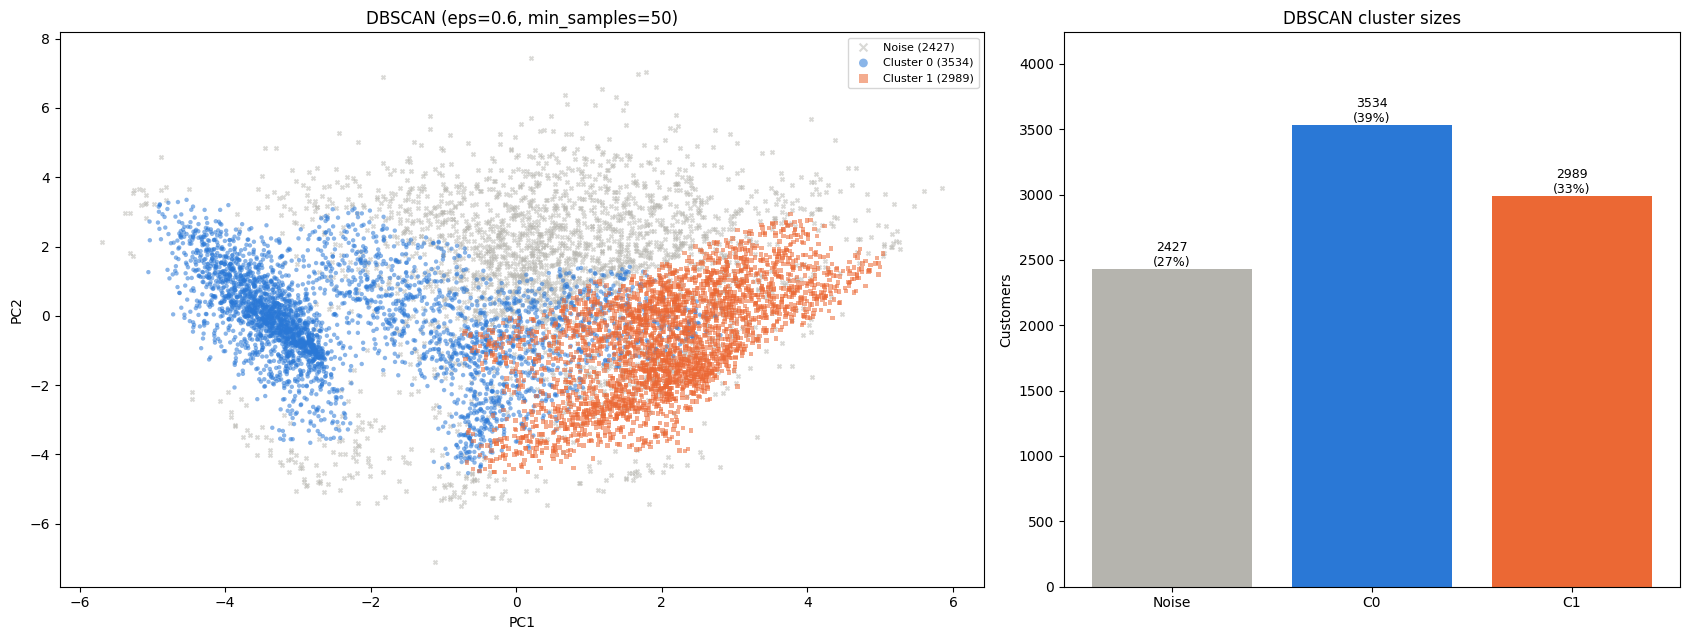

In [57]:
dbscan = DBSCAN(eps=BEST_EPS, min_samples=BEST_MS)
dbscan_labels = dbscan.fit_predict(X_db)

n_clusters_db = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
n_noise_db = int(np.sum(dbscan_labels == -1))
db_scores = evaluate(X_scaled, dbscan_labels, ignore_noise=True)   # scored in the same 17-D space as the others

print(f"Tuned DBSCAN (eps={BEST_EPS}, min_samples={BEST_MS}) on 3 PCA components")
print(f"  clusters           : {n_clusters_db}")
print(f"  noise points       : {n_noise_db} ({n_noise_db / len(dbscan_labels):.1%})")
for name, v in db_scores.items():
    print(f"  {name:<18}: {v:.4f}   (non-noise points, 17-D space)")

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw={'width_ratios': [1.5, 1]})
plot_clusters_2d(dbscan_labels, f'DBSCAN (eps={BEST_EPS}, min_samples={BEST_MS})', ax=axes[0])
plot_cluster_sizes(dbscan_labels, 'DBSCAN cluster sizes', ax=axes[1])
plt.tight_layout(); plt.show()

### What DBSCAN is telling us
* DBSCAN finds **two dense cores**: roughly *customers who mainly use cash advances* (left, cluster 0) and *customers who mainly make purchases* (right, cluster 1).
* About a quarter of customers fall in the **sparse region between and above them** and are labelled noise. The table below shows these are not "errors": they are customers who **both purchase and take cash advances**, with higher balances and credit limits – a mixed, less common behaviour.
* Customer behaviour forms a **continuum** rather than islands separated by empty space, so a density-based method cannot split it into many clean segments. DBSCAN is still useful here for spotting the **dense "typical" behaviours** and flagging the **unusual** customers for a separate look (e.g., by a risk team).

In [58]:
# How do DBSCAN's noise points differ from everyone else? (median values, real units)
compare_cols = ['BALANCE', 'PURCHASES', 'CASH_ADVANCE', 'CREDIT_LIMIT', 'PAYMENTS', 'PRC_FULL_PAYMENT']
noise_vs_rest = pd.DataFrame({
    'Noise (median)':     X_original[dbscan_labels == -1][compare_cols].median(),
    'Clustered (median)': X_original[dbscan_labels != -1][compare_cols].median()
}).round(2)
noise_vs_rest

,Noise (median),Clustered (median)
BALANCE,1625.25,625.29
PURCHASES,759.15,247.50
CASH_ADVANCE,553.50,0.00
CREDIT_LIMIT,5000.00,3000.00
PAYMENTS,1442.25,706.15
PRC_FULL_PAYMENT,0.00,0.00


# 8. Comparing the Three Algorithms

In [59]:
comparison = pd.DataFrame({
    'K-Means':                     {**km_scores,  'n_clusters': BEST_K,        'noise_%': 0.0},
    f'Agglomerative ({AGG_LINKAGE})': {**agg_scores, 'n_clusters': BEST_K,        'noise_%': 0.0},
    'DBSCAN':                      {**db_scores,  'n_clusters': n_clusters_db, 'noise_%': 100 * n_noise_db / len(dbscan_labels)},
}).T
comparison = comparison[['n_clusters', 'noise_%', 'silhouette', 'davies_bouldin', 'calinski_harabasz']]

# Highlight the best value in each metric column
(comparison.style
     .format({'n_clusters': '{:.0f}', 'noise_%': '{:.1f}', 'silhouette': '{:.3f}',
              'davies_bouldin': '{:.3f}', 'calinski_harabasz': '{:.0f}'})
     .highlight_max(subset=['silhouette', 'calinski_harabasz'], color='#cfe3f7')
     .highlight_min(subset=['davies_bouldin'], color='#cfe3f7'))

,n_clusters,noise_%,silhouette,davies_bouldin,calinski_harabasz
K-Means,4,0.0,0.216,1.683,2256
Agglomerative (ward),4,0.0,0.175,1.878,1762
DBSCAN,2,27.1,0.293,1.403,2934


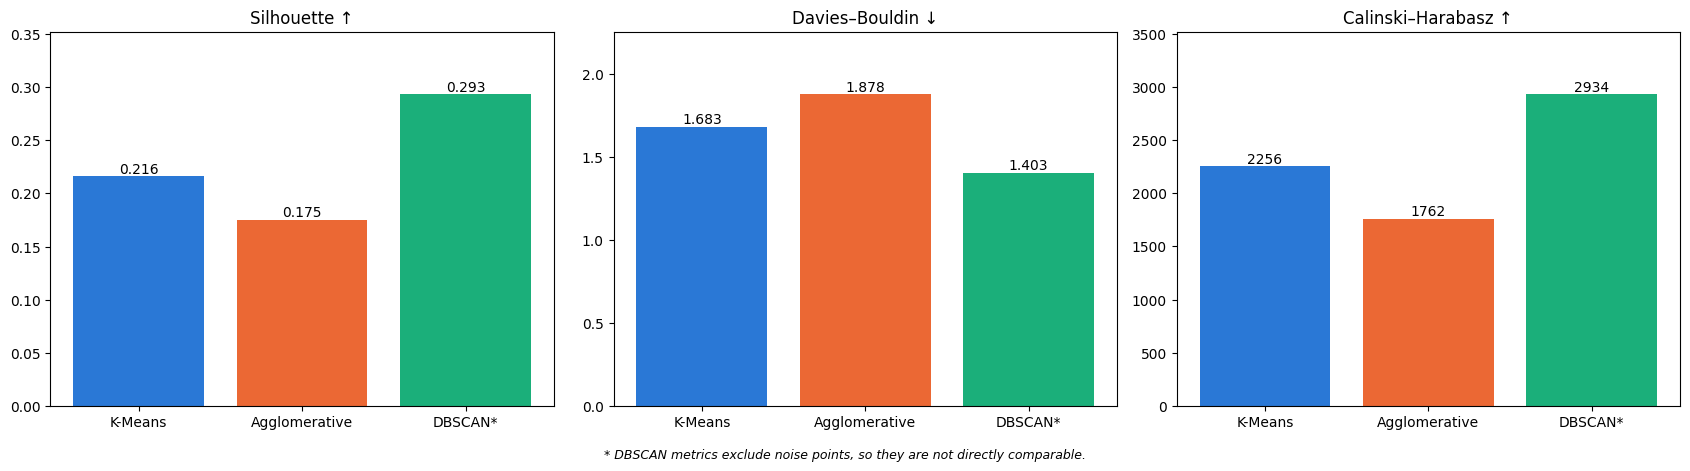

In [60]:
# Bar charts of each metric (one chart per metric - they have very different scales)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
names = ['K-Means', 'Agglomerative', 'DBSCAN*']
metric_info = [('silhouette', 'Silhouette ↑'), ('davies_bouldin', 'Davies–Bouldin ↓'),
               ('calinski_harabasz', 'Calinski–Harabasz ↑')]
for ax, (col, title) in zip(axes, metric_info):
    vals = comparison[col].values
    bars = ax.bar(names, vals, color=CLUSTER_COLORS[:3])
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v, f'{v:.3f}' if v < 100 else f'{v:.0f}',
                ha='center', va='bottom', fontsize=10)
    ax.set_title(title); ax.set_ylim(0, vals.max() * 1.2)
fig.text(0.5, -0.03, '* DBSCAN metrics exclude noise points, so they are not directly comparable.',
         ha='center', fontsize=9, style='italic')
plt.tight_layout(); plt.show()

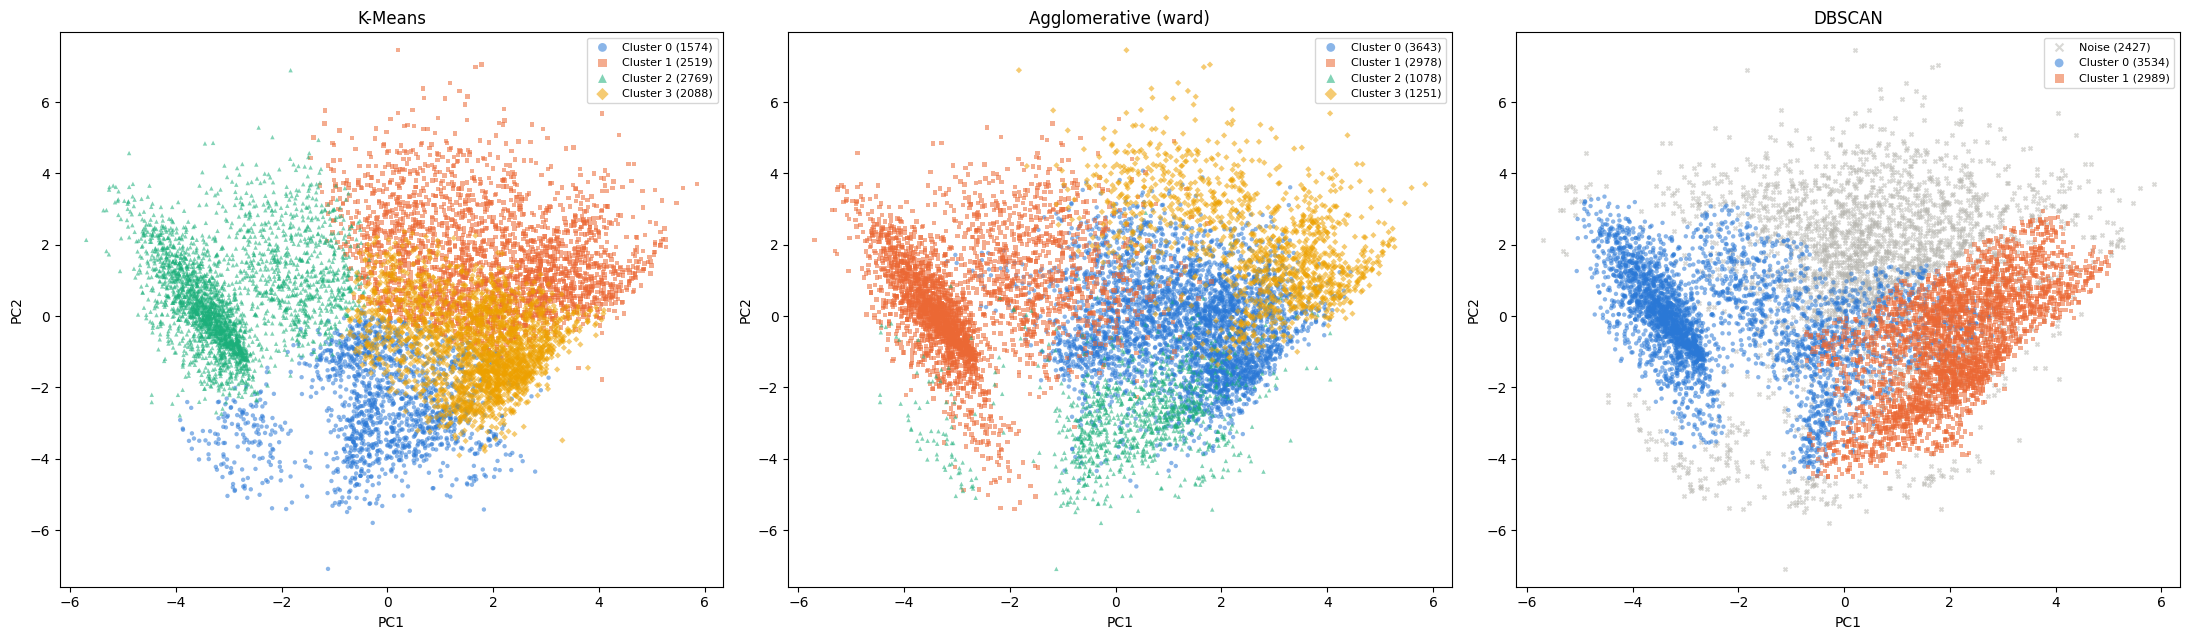

In [61]:
# Side-by-side scatter plots of all three final models
fig, axes = plt.subplots(1, 3, figsize=(22, 6.5))
plot_clusters_2d(kmeans_labels, 'K-Means', ax=axes[0])
plot_clusters_2d(agg_labels, f'Agglomerative ({AGG_LINKAGE})', ax=axes[1])
plot_clusters_2d(dbscan_labels, 'DBSCAN', ax=axes[2])
for ax in axes:
    ax.set_xlim(X_pca[:, 0].min() - 0.5, X_pca[:, 0].max() + 0.5)
    ax.set_ylim(X_pca[:, 1].min() - 0.5, X_pca[:, 1].max() + 0.5)
plt.tight_layout(); plt.show()

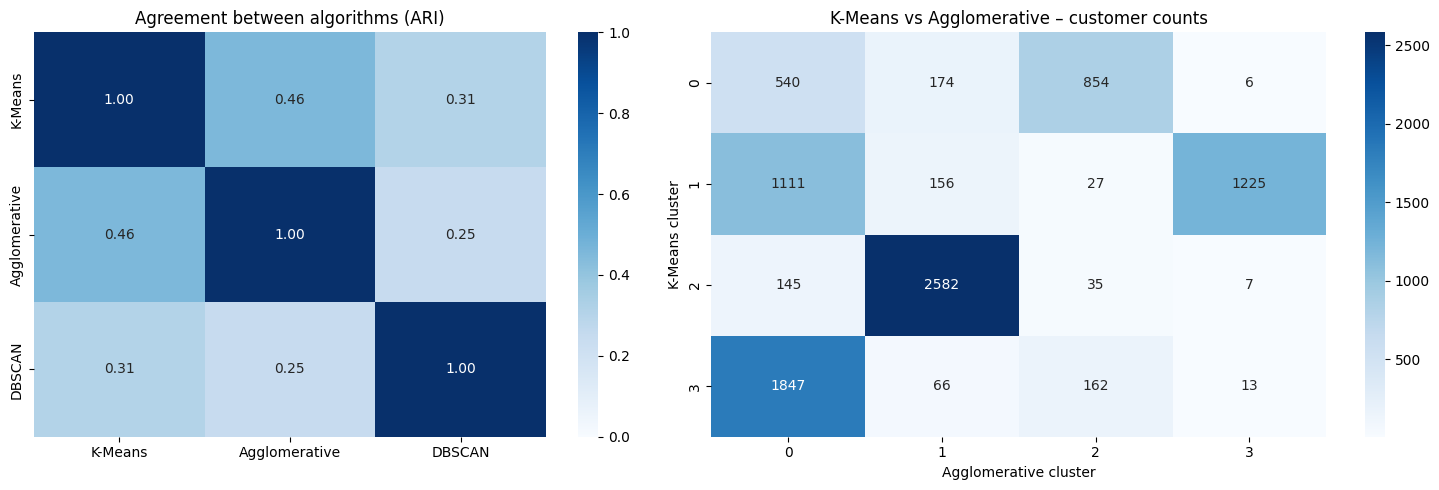

In [62]:
# Do the algorithms agree?  Adjusted Rand Index (ARI): 1 = identical grouping, 0 = random agreement.
all_labels = {'K-Means': kmeans_labels, 'Agglomerative': agg_labels, 'DBSCAN': dbscan_labels}
ari = pd.DataFrame([[adjusted_rand_score(all_labels[a], all_labels[b]) for b in all_labels]
                    for a in all_labels], index=all_labels, columns=all_labels)

fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={'width_ratios': [1, 1.2]})
sns.heatmap(ari, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1, ax=axes[0])
axes[0].set_title('Agreement between algorithms (ARI)')

# Cross-tab: which K-Means cluster do Agglomerative clusters map to?
ct = pd.crosstab(pd.Series(kmeans_labels, name='K-Means cluster'),
                 pd.Series(agg_labels, name='Agglomerative cluster'))
sns.heatmap(ct, annot=True, fmt='d', cmap='Blues', ax=axes[1])
axes[1].set_title('K-Means vs Agglomerative – customer counts')
plt.tight_layout(); plt.show()

### Verdict
* **DBSCAN's** scores look best, but remember the trap from Section 7: they are computed **only on the ~73% of customers it kept** – the hardest 27% were thrown away as noise, and it found only 2 clusters. That is not a fair win.
* **K-Means** beats Agglomerative on all three metrics, uses **every** customer, and produces evenly sized, interpretable segments → **our final model for segmentation.**
* **Agglomerative (Ward)** finds broadly similar structure (see the cross-tab) and the dendrogram is a great tool for *understanding* hierarchy, but its scores are a bit lower and it is slow on very large datasets (memory grows with n²).
* **DBSCAN** is not suited to segmenting this dataset (no density gaps), but is valuable for **flagging unusual customers**.

# 9. Cluster Profiling – What Does Each K-Means Segment Mean?
Numbers like "cluster 2" are meaningless to a business. We describe each cluster using the **original, un-scaled** values.

In [63]:
df_final = X_original.copy()
df_final['Cluster'] = kmeans_labels

# Mean value of every feature per cluster (real units)
profile = df_final.groupby('Cluster').mean().T
profile['Overall'] = X_original.mean()
profile.round(2)

Cluster,0,1,2,3,Overall
BALANCE,212.70,2258.14,2455.69,564.75,1564.47
BALANCE_FREQUENCY,0.53,0.98,0.94,0.93,0.88
PURCHASES,355.35,2639.77,103.94,709.75,1003.20
ONEOFF_PURCHASES,274.91,1784.55,79.79,73.46,592.44
INSTALLMENTS_PURCHASES,80.82,855.29,24.19,637.16,411.07
CASH_ADVANCE,111.62,866.01,2216.55,127.45,978.87
PURCHASES_FREQUENCY,0.26,0.83,0.08,0.81,0.49
ONEOFF_PURCHASES_FREQUENCY,0.11,0.56,0.04,0.04,0.20
PURCHASES_INSTALLMENTS_FREQUENCY,0.13,0.55,0.03,0.76,0.36
CASH_ADVANCE_FREQUENCY,0.02,0.11,0.30,0.02,0.14


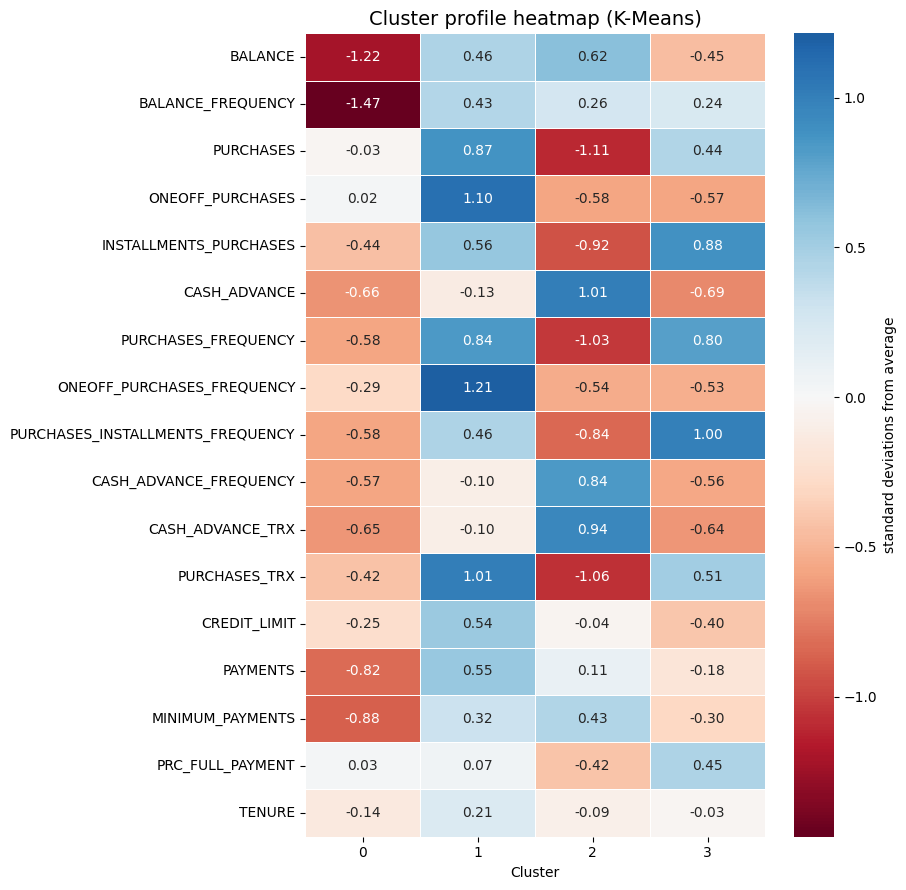

In [64]:
# Heatmap of cluster means expressed as z-scores relative to the overall population.
# Blue = above average, red = below average. Easier to read than raw numbers.
cluster_means_scaled = pd.DataFrame(X_scaled, columns=X.columns).groupby(kmeans_labels).mean().T

plt.figure(figsize=(9, 9))
sns.heatmap(cluster_means_scaled, cmap='RdBu', center=0, annot=True, fmt='.2f',
            linewidths=0.5, cbar_kws={'label': 'standard deviations from average'})
plt.title('Cluster profile heatmap (K-Means)', fontsize=14)
plt.xlabel('Cluster'); plt.tight_layout(); plt.show()

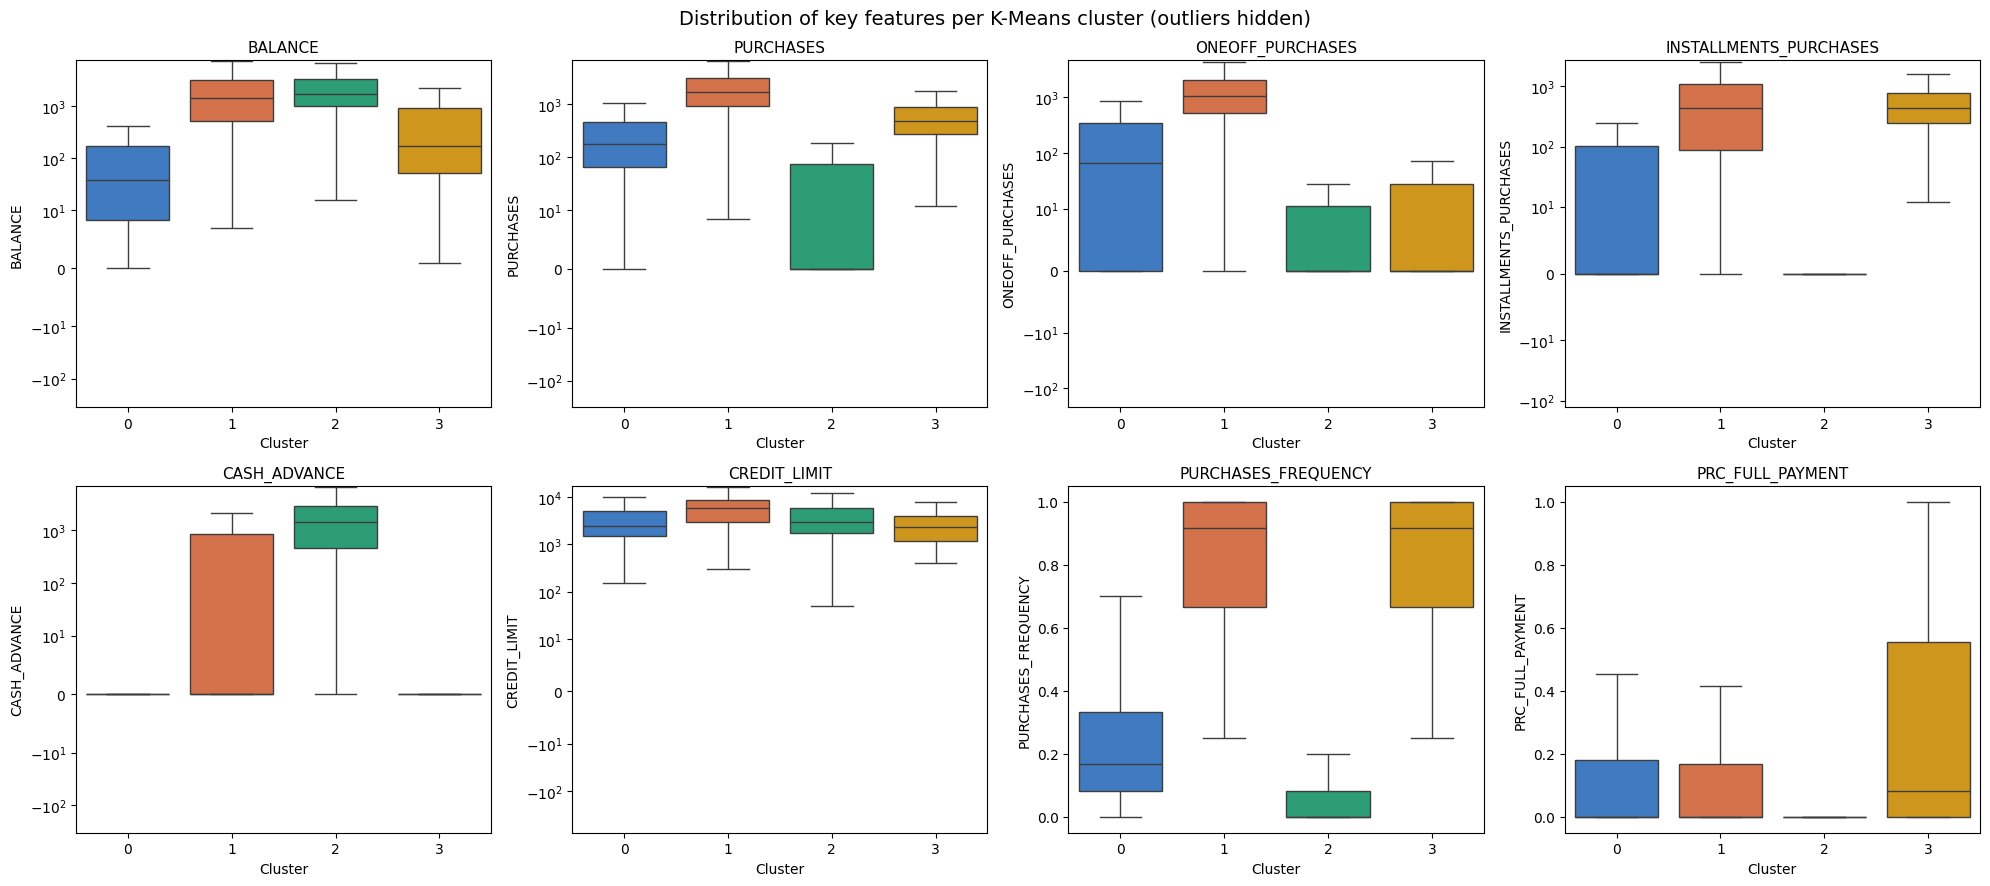

In [65]:
# Box plots of key features per cluster (log scale for money columns because of the long tails)
key_features = ['BALANCE', 'PURCHASES', 'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES',
                'CASH_ADVANCE', 'CREDIT_LIMIT', 'PURCHASES_FREQUENCY', 'PRC_FULL_PAYMENT']
palette = {i: CLUSTER_COLORS[i] for i in range(BEST_K)}

fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, col in zip(axes.flat, key_features):
    sns.boxplot(data=df_final, x='Cluster', y=col, hue='Cluster', palette=palette,
                ax=ax, showfliers=False, legend=False)
    if col in skewed_cols or col in ['CREDIT_LIMIT', 'ONEOFF_PURCHASES']:
        ax.set_yscale('symlog', linthresh=10)
    ax.set_title(col, fontsize=11); ax.set_xlabel('Cluster')
plt.suptitle('Distribution of key features per K-Means cluster (outliers hidden)', fontsize=14)
plt.tight_layout(); plt.show()

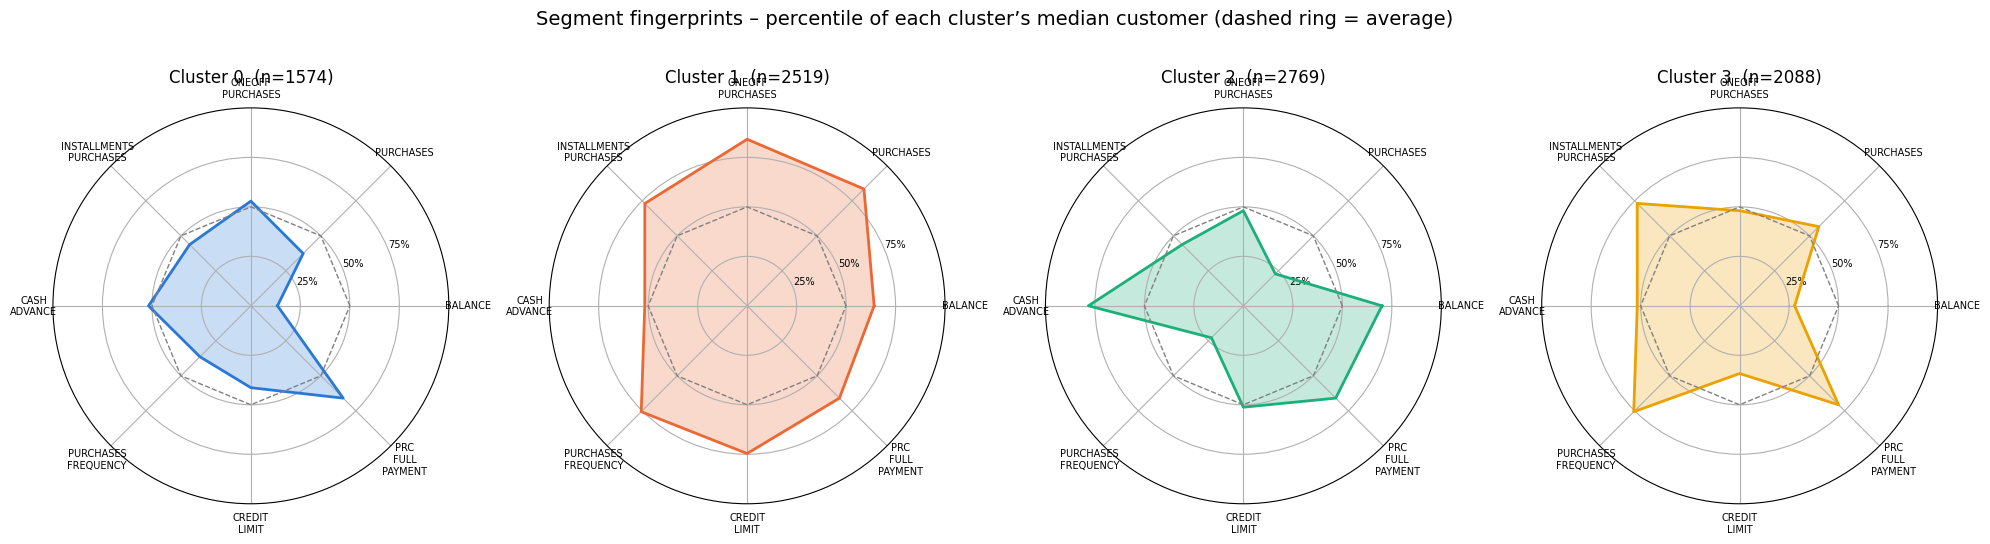

In [66]:
# Radar (spider) chart: a compact "fingerprint" of each segment.
radar_features = ['BALANCE', 'PURCHASES', 'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES',
                  'CASH_ADVANCE', 'PURCHASES_FREQUENCY', 'CREDIT_LIMIT', 'PRC_FULL_PAYMENT']
# Put every axis on the same 0-1 scale using PERCENTILES:
# "the typical (median) customer of this cluster sits at the X-th percentile of ALL customers".
# 0.5 = average customer, 0.9 = higher than 90% of customers.
med = df_final.groupby('Cluster')[radar_features].median()
med_norm = med.apply(lambda col: col.map(lambda v: (X_original[col.name] <= v).mean()))

angles = np.linspace(0, 2 * np.pi, len(radar_features), endpoint=False).tolist()
angles += angles[:1]   # close the loop

fig, axes = plt.subplots(1, BEST_K, figsize=(5 * BEST_K, 5), subplot_kw=dict(polar=True))
for c, ax in zip(med_norm.index, axes):
    vals = med_norm.loc[c].tolist() + [med_norm.loc[c].tolist()[0]]
    ax.plot(angles, vals, color=CLUSTER_COLORS[c], lw=2)
    ax.fill(angles, vals, color=CLUSTER_COLORS[c], alpha=0.25)
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels([f.replace('_', '\n') for f in radar_features], fontsize=7)
    ax.plot(angles, [0.5] * len(angles), color='grey', ls='--', lw=1)   # dashed ring = average customer
    ax.set_yticks([0.25, 0.5, 0.75]); ax.set_yticklabels(['25%', '50%', '75%'], fontsize=7)
    ax.set_ylim(0, 1)
    ax.set_title(f'Cluster {c}  (n={np.sum(kmeans_labels == c)})', color='black', pad=18)
plt.suptitle('Segment fingerprints – percentile of each cluster’s median customer (dashed ring = average)', fontsize=14, y=1.05)
plt.tight_layout(); plt.show()

In [67]:
# Median table in real units - the numbers you would quote in a report
summary_cols = ['BALANCE', 'PURCHASES', 'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES',
                'CASH_ADVANCE', 'PURCHASES_FREQUENCY', 'CASH_ADVANCE_FREQUENCY',
                'CREDIT_LIMIT', 'PAYMENTS', 'PRC_FULL_PAYMENT']
median_table = df_final.groupby('Cluster')[summary_cols].median().round(2)
median_table['Customers'] = df_final['Cluster'].value_counts().sort_index()
median_table

,BALANCE,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,CASH_ADVANCE_FREQUENCY,CREDIT_LIMIT,PAYMENTS,PRC_FULL_PAYMENT,Customers
Cluster,,,,,,,,,,,
0,37.87,177.50,66.35,0.0,0.00,0.17,0.00,2500.0,319.65,0.00,1574
1,1396.28,1699.87,1060.66,429.0,0.00,0.92,0.00,6000.0,1844.39,0.00,2519
2,1698.37,0.00,0.00,0.0,1405.78,0.00,0.25,3000.0,883.94,0.00,2769
3,166.90,484.58,0.00,431.4,0.00,0.92,0.00,2300.0,587.71,0.08,2088


### Customer personas (K-Means, k = 4)
Read the heatmap, box plots and radar charts together. *(Averages below come from the profile table above. Cluster numbers stay the same as long as `random_state=42` and the preprocessing are unchanged.)*

| Cluster | Persona | Size | What defines them | Possible business action |
|---|---|---|---|---|
| **0** | 💤 **Inactive / Low-engagement users** | ~18% | Lowest balance (avg ≈ \$210), balance updated only about half the months (0.53), few purchases (~4 transactions), almost no cash advances | Re-activation campaigns, welcome-back offers, check if cards are used elsewhere |
| **1** | 💎 **High-value all-round spenders** | ~28% | Highest purchases (avg ≈ \$2,640) with both one-off **and** installment buying, ~36 purchase transactions, highest credit limit (≈ \$6,440), highest payments | Premium rewards / cashback cards, credit-limit increases, loyalty programmes |
| **2** | 💸 **Cash-advance revolvers** | ~31% | High balance (≈ \$2,460) and heavy cash advances (≈ \$2,220), rarely buy anything (purchase frequency 0.08), almost never pay in full (3% of months) | Credit-risk monitoring; offer balance-transfer or instalment-loan products; financial-wellness messaging |
| **3** | 🛒 **Installment shoppers / careful payers** | ~23% | Frequent installment purchases (frequency 0.76), low balance (≈ \$565), the **best full-payment rate** (29%), lowest credit limit | Promote 0% installment plans with partner stores; reward good repayment with limit increases |

💡 **Notice how this matches DBSCAN:** its two dense cores are essentially "cash-advance users" (≈ cluster 2) and "purchasers" (≈ clusters 1 & 3).

In [68]:
# Attach labels from all three models to the original dataframe and save
df_out = df.copy()
df_out['KMeans_Cluster'] = kmeans_labels
df_out['Agg_Cluster'] = agg_labels
df_out['DBSCAN_Cluster'] = dbscan_labels   # -1 = noise / unusual customer
df_out.to_csv('credit_card_clusters.csv', index=False)
print("Saved credit_card_clusters.csv")
df_out[['CUST_ID', 'KMeans_Cluster', 'Agg_Cluster', 'DBSCAN_Cluster']].head()

Saved credit_card_clusters.csv


,CUST_ID,KMeans_Cluster,Agg_Cluster,DBSCAN_Cluster
0,C10001,0,2,-1
1,C10002,2,1,0
2,C10003,1,0,0
3,C10004,0,2,0
4,C10005,0,0,0


# 10. Summary & Key Lessons

### What changed from the first version
| | Original notebook | Refined notebook |
|---|---|---|
| Preprocessing | Median impute + scale | Median impute + **log transform of skewed features** + scale |
| K-Means | *k* = 4 guessed, silhouette 0.198 | *k* chosen with 4 metrics, `n_init=50`, silhouette **0.216** |
| Agglomerative | Ward, *k* = 4, silhouette 0.160 | Linkage × *k* grid search with a minimum-cluster-size rule; Ward, silhouette **0.175** |
| DBSCAN | `eps=2.5` → **1 cluster** + 341 noise | PCA space + k-distance plot + 105-config grid → **2 clusters**, 27% noise |
| Visuals | none | EDA, PCA, elbow/metric curves, silhouette plots, dendrogram, heatmaps, 2D/3D scatter, profiles, radar charts |
| Interpretation | none | 4 business personas |

> Silhouette scores computed on differently preprocessed data are not strictly comparable – the bigger win from the log transform is **balanced, meaningful clusters** (on the raw data K-Means creates tiny clusters of a few dozen extreme customers).

### Key lessons to remember
1. **Preprocessing shapes the clusters.** Scaling is mandatory for distance-based methods; log-transforming skewed money features stops a few extreme customers from dominating.
2. **There is rarely one "correct" *k*.** Use several metrics to narrow the range, then choose for interpretability – and say so.
3. **Never trust a metric without checking cluster sizes.** High silhouette can mean "one giant cluster + a few outliers" (average/single linkage) or "throw most points away as noise" (DBSCAN).
4. **DBSCAN needs density gaps** and suffers in high dimensions – reduce dimensions first and tune `eps` with a k-distance plot.
5. **Clusters are only useful once you can describe them** in business language.